# Income Prediction

The goal of the project is to predict a client's income

Load the required libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant
from sklearn.preprocessing import StandardScaler
from sklearn.impute import KNNImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_absolute_percentage_error
import statsmodels.api as sm
from xgboost import XGBRegressor 
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold
from sklearn.inspection import permutation_importance
from sklearn.base import clone
from sklearn.inspection import PartialDependenceDisplay
import shap

Let's see what the data looks like

In [3]:
df=pd.read_excel("income data.xlsx",sheet_name='income_data')
df.head()

,target,Inc_Past,Liab_Tot,Inc_in,Transfers_out,Payment_L,Min_transfer_In,Turnover,Transactions,Salary,...,Transfers_in,Trn_max,Balance,Loan,Payments,Inc_Past_avg,Inc_Past_max,Tot_in,Bal_Cur,Loan_Cnt
0,2181,2777.195785,44602.771367,2653.0275,4403.502844,1376.27,2665.9753,2034.681741,4791.205440,1818,...,2531,50122.787705,3340.0,739.314898,60467.242121,0.000000,1676.276897,43645.292490,2335.885221,0.0
1,2234,2990.621878,69743.054007,2846.3787,14301.294615,1273.84,757.6630,4533.526273,26399.439740,528,...,788,29988.399052,1109.0,3470.616261,314169.073224,3705.778804,8561.789769,194165.567817,9558.020208,0.0
2,550,0.000000,10204.333221,650.8682,1091.498280,378.60,0.0000,636.005285,634.152829,264,...,369,117251.845035,4226.0,0.000000,0.000000,1653.192006,0.000000,0.000000,0.000000,0.0
3,1998,5054.195547,26858.856944,2163.8332,6881.157648,1823.42,1910.0083,5390.744004,6555.062441,1490,...,821,31746.542498,668.0,0.000000,127750.487939,1613.766044,450.630630,119729.437108,4571.733008,7.0
4,1493,2308.910985,6290.469562,1072.9084,1907.841516,933.49,1052.4194,1288.780352,2222.979571,1564,...,1409,229239.551743,943.0,2911.261656,22783.555228,1241.377471,2630.575931,18645.055929,1969.973314,0.0


## Exploratory Data Analysis

Univariate Analysis

Look at the structure of the data

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 22 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   target           100000 non-null  int64  
 1   Inc_Past         97608 non-null   float64
 2   Liab_Tot         95843 non-null   float64
 3   Inc_in           100000 non-null  float64
 4   Transfers_out    99833 non-null   float64
 5   Payment_L        85850 non-null   float64
 6   Min_transfer_In  100000 non-null  float64
 7   Turnover         97682 non-null   float64
 8   Transactions     99794 non-null   float64
 9   Salary           100000 non-null  int64  
 10  Inc_6M           100000 non-null  int64  
 11  Acct_Trns        99745 non-null   float64
 12  Transfers_in     100000 non-null  int64  
 13  Trn_max          99769 non-null   float64
 14  Balance          99908 non-null   float64
 15  Loan             100000 non-null  float64
 16  Payments         99806 non-null   float64
 17  Inc

The data has 100,000 records, 21 independent variables and one dependent (target) variable.

Note that all variables are numeric; there are no categorical variables in the data.

It is also important that every value of the dependent variable is filled in.

Go through the meaning of each variable in detail

| Variable | Description |
| --- | --- |
| target | Target (client income) |
| Inc_Past | Client's past income |
| Liab_Tot | Client's liabilities |
| Inc_in | Client's incoming payments |
| Transfers_out | Transfers from the account |
| Payment_L | Monthly payment |
| Min_transfer_In | Client's minimum incoming payment |
| Turnover | Account turnover |
| Transactions | Transactions from the account |
| Salary | Salary |
| Inc_6M | Incoming payments over 6 months |
| Acct_Trns | Outgoing transfers from the account |
| Transfers_in | Amounts received on the account |
| Trn_max | Maximum outgoing transfer from the account |
| Balance | Account balance |
| Loan | Loan amount |
| Payments | Payments |
| Inc_Past_avg | Client's past average income |
| Inc_Past_max | Client's past maximum income |
| Tot_in | Total incoming payments on the account |
| Bal_Cur | Current balance |
| Loan_Cnt | Number of loans |

Check for duplicates

In [5]:
df.duplicated().sum()

np.int64(0)

Look at the share of missing values in each variable

In [6]:
def missing_values(df):
    missing=df.isnull().sum()
    missing_percent=(missing / len(df)) * 100
    missing_df=pd.DataFrame({
        'Feature': missing.index,
        'Missing Count': missing.values,
        'Missing Percentage %': (missing_percent.values)
    })
    return missing_df.sort_values('Missing Percentage %', ascending=False)

            Feature  Missing Count  Missing Percentage %
5         Payment_L          14150                14.150
21         Loan_Cnt           6163                 6.163
2          Liab_Tot           4157                 4.157
1          Inc_Past           2392                 2.392
17     Inc_Past_avg           2379                 2.379
18     Inc_Past_max           2334                 2.334
7          Turnover           2318                 2.318
11        Acct_Trns            255                 0.255
19           Tot_in            239                 0.239
13          Trn_max            231                 0.231
8      Transactions            206                 0.206
16         Payments            194                 0.194
4     Transfers_out            167                 0.167
20          Bal_Cur            129                 0.129
14          Balance             92                 0.092
0            target              0                 0.000
3            Inc_in            

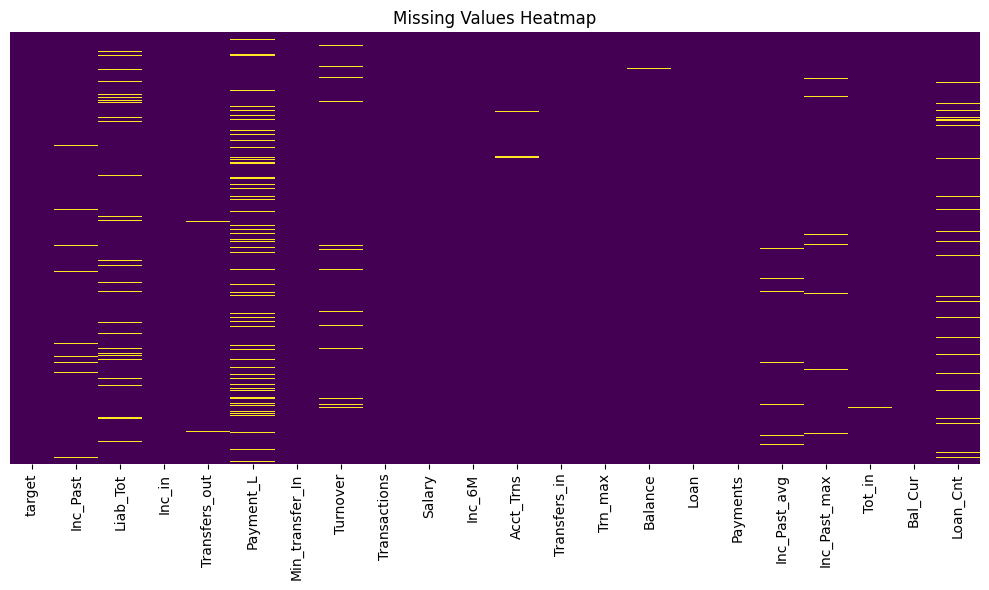

In [7]:
print(missing_values(df))

# build the corresponding heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis', yticklabels=False)
plt.title('Missing Values Heatmap')
plt.tight_layout()
plt.show()

Most variables have missing values, but their share is low in most cases, which lets us impute the data. The share of missing data is especially high in 'Payment_L', about 14%.

Look at the distribution of the variables and their summary statistics

target
Mean: 2541.77
Standard Deviation: 1929.36
Min: 200
Q1: 1167.0
Median: 1982.0
Q3: 3285.0
Max: 10000


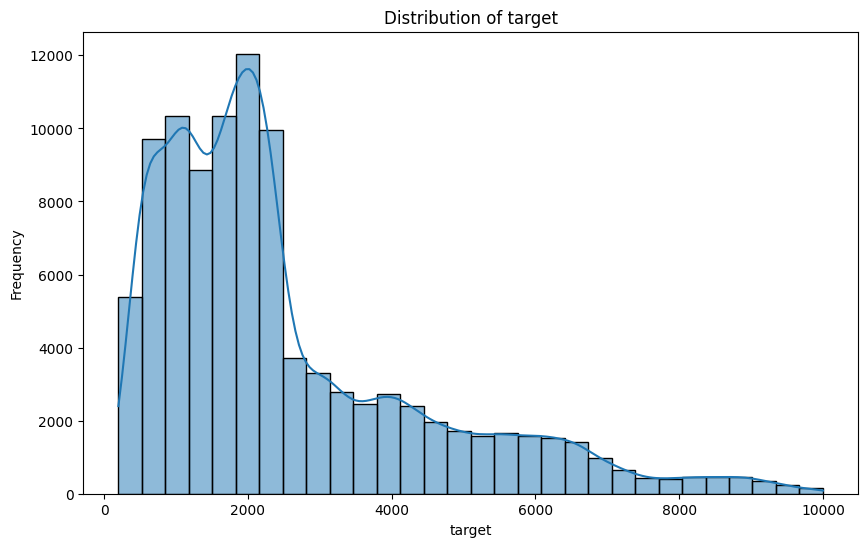



Inc_Past
Mean: 2001.69
Standard Deviation: 1751.38
Min: 0.0
Q1: 873.46
Median: 1587.82
Q3: 2541.16
Max: 16693.17


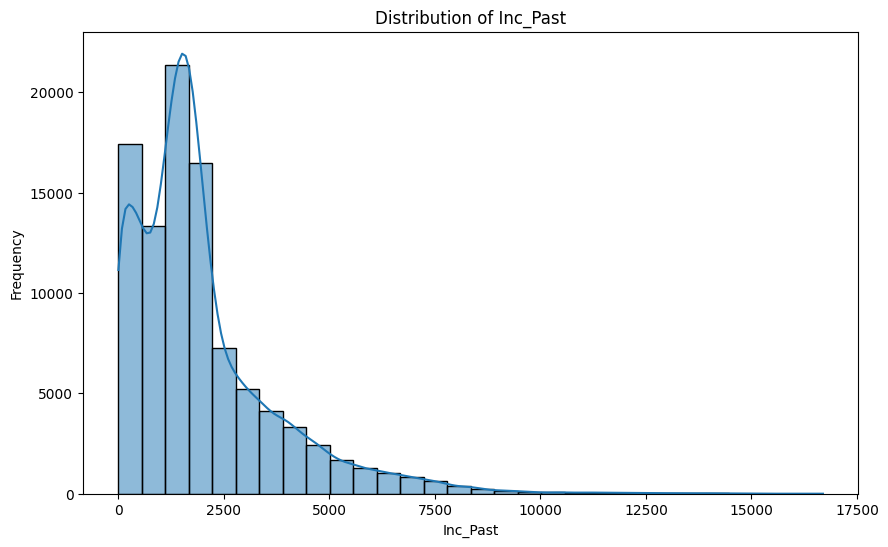



Liab_Tot
Mean: 33654.67
Standard Deviation: 53118.87
Min: 0.0
Q1: 4283.78
Median: 12967.5
Q3: 31857.71
Max: 355931.23


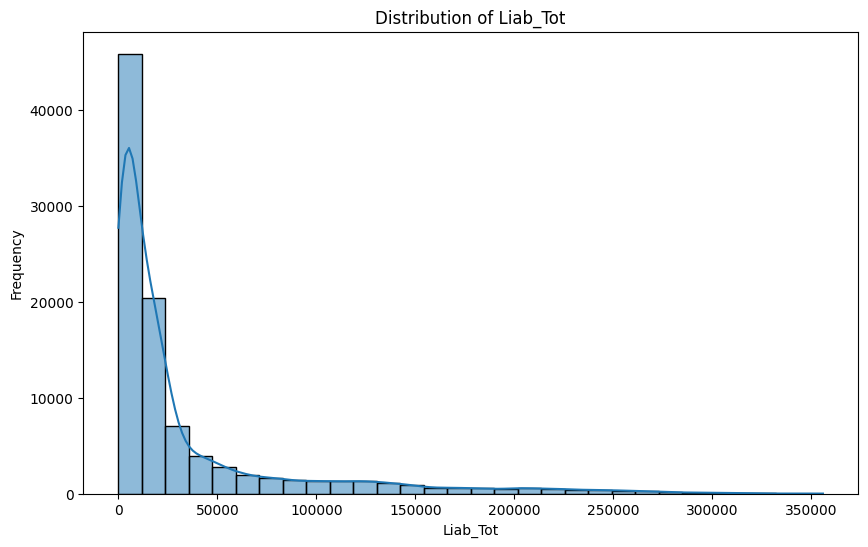



Inc_in
Mean: 2564.98
Standard Deviation: 2429.02
Min: 0.0
Q1: 1124.7
Median: 1742.88
Q3: 2904.6
Max: 21503.6


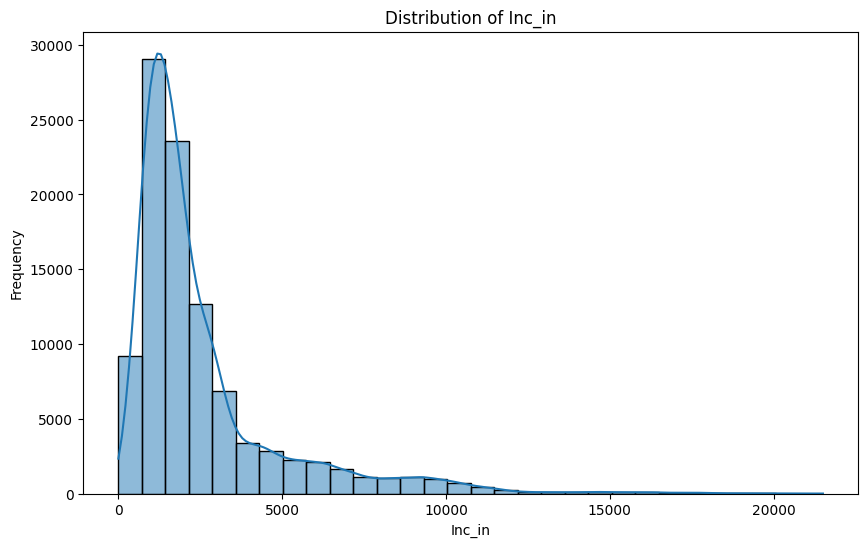



Transfers_out
Mean: 8311.28
Standard Deviation: 11918.3
Min: 0.0
Q1: 2037.42
Median: 3656.71
Q3: 10629.59
Max: 91312.36


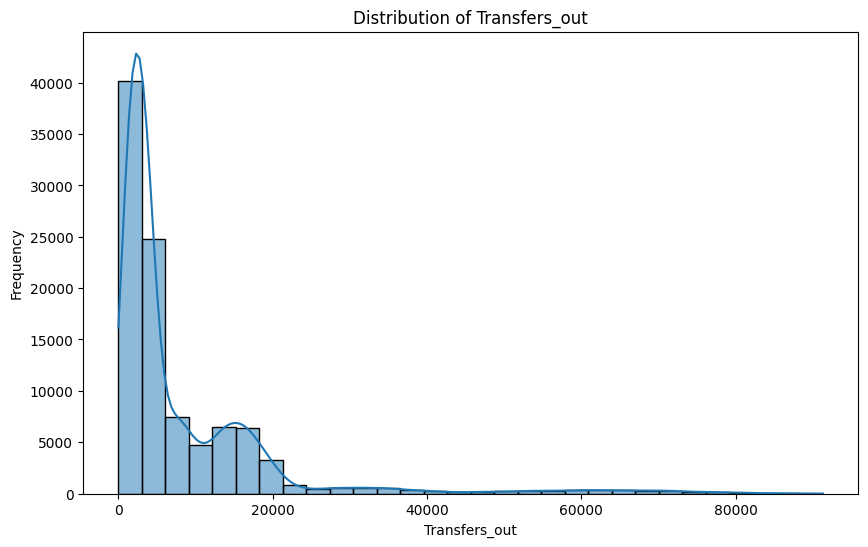



Payment_L
Mean: 1217.97
Standard Deviation: 1259.23
Min: 0.0
Q1: 375.06
Median: 926.9
Q3: 1581.34
Max: 8718.1


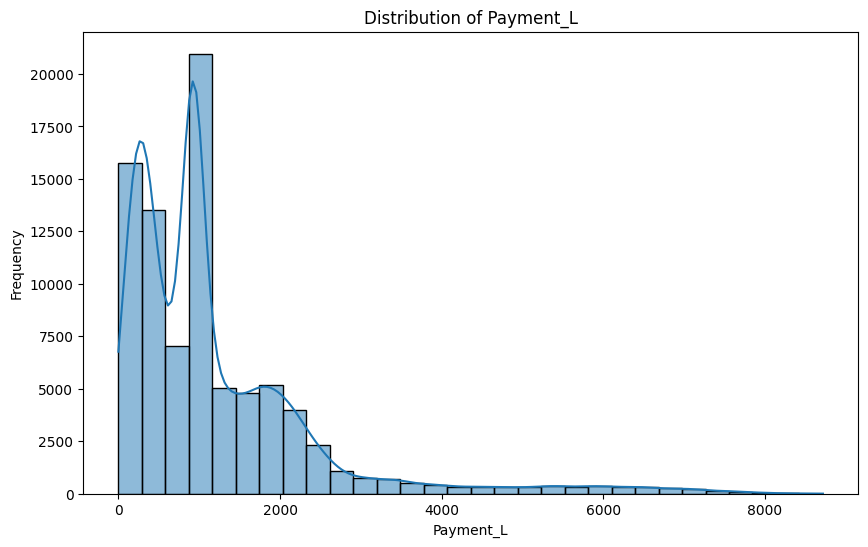



Min_transfer_In
Mean: 2067.81
Standard Deviation: 1971.5
Min: 0.0
Q1: 886.93
Median: 1514.59
Q3: 2603.21
Max: 12862.64


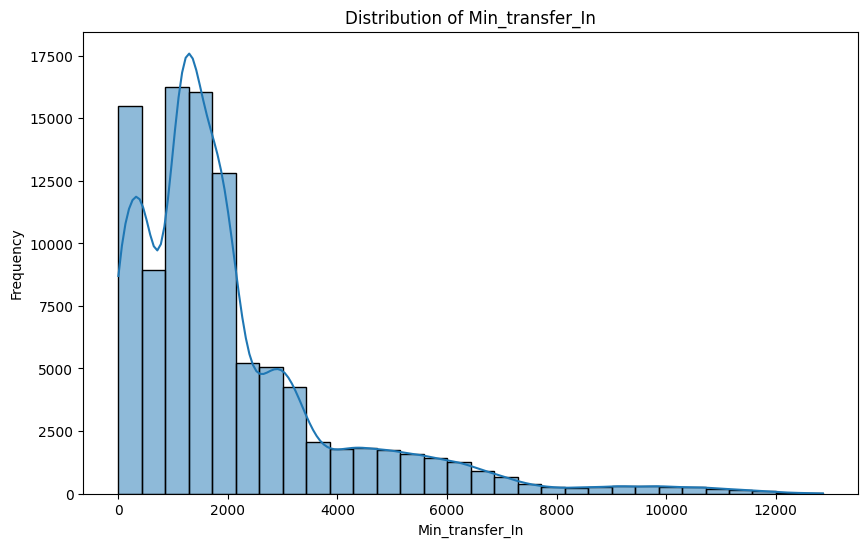



Turnover
Mean: 2337.35
Standard Deviation: 2430.45
Min: 0.0
Q1: 838.06
Median: 1642.37
Q3: 2999.32
Max: 19414.71


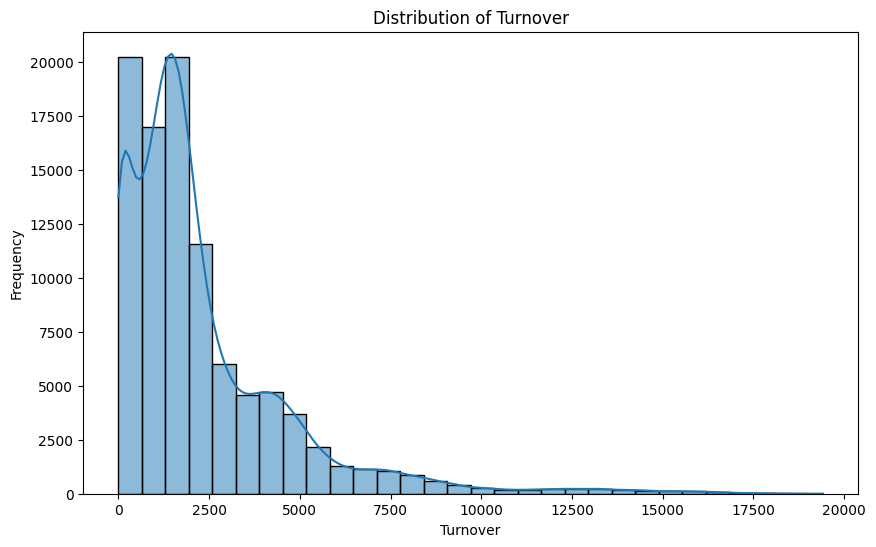



Transactions
Mean: 9241.56
Standard Deviation: 11874.89
Min: 0.0
Q1: 2270.43
Median: 4964.55
Q3: 9704.13
Max: 81173.16


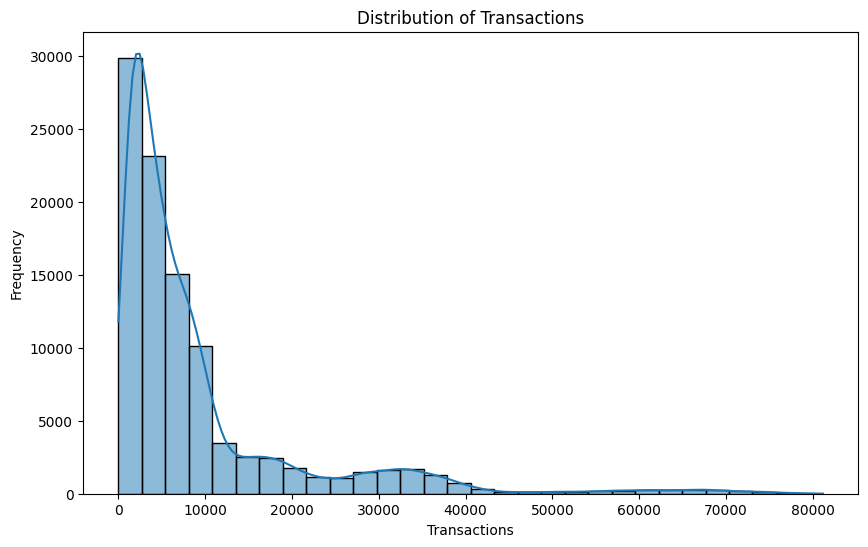



Salary
Mean: 1763.16
Standard Deviation: 1748.09
Min: 0
Q1: 686.0
Median: 1310.0
Q3: 2010.0
Max: 11855


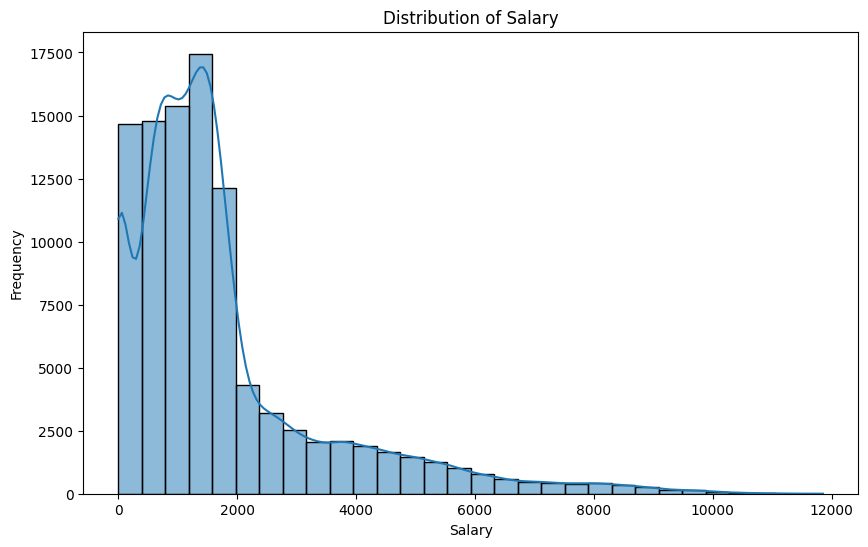



Inc_6M
Mean: 1481.37
Standard Deviation: 1573.73
Min: 0
Q1: 510.0
Median: 1033.0
Q3: 1910.0
Max: 11823


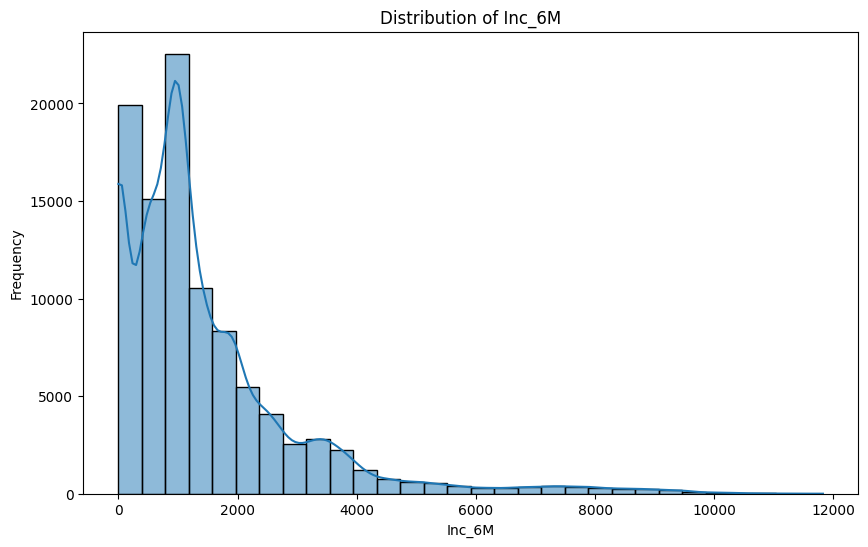



Acct_Trns
Mean: 8992.2
Standard Deviation: 13076.5
Min: 0.0
Q1: 2273.1
Median: 4407.81
Q3: 9722.53
Max: 116128.53


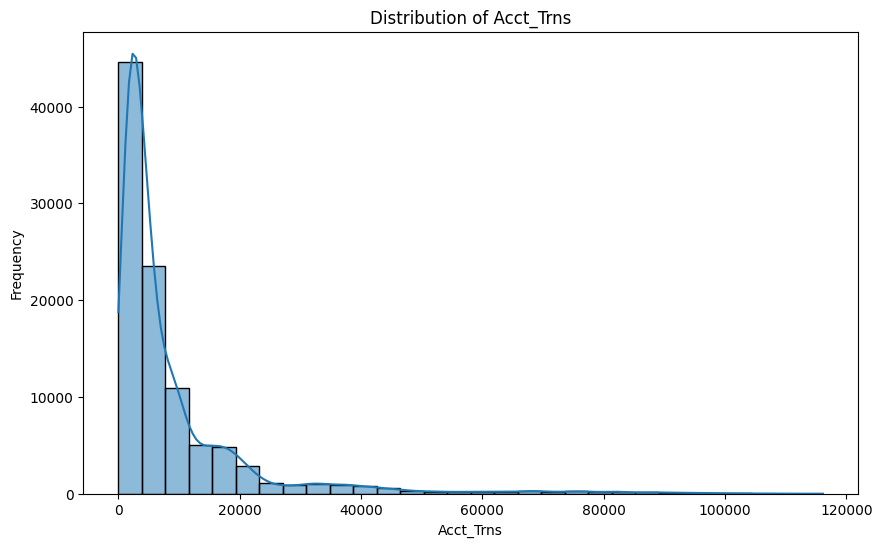



Transfers_in
Mean: 1875.58
Standard Deviation: 1828.27
Min: 0
Q1: 769.0
Median: 1357.0
Q3: 2387.0
Max: 12303


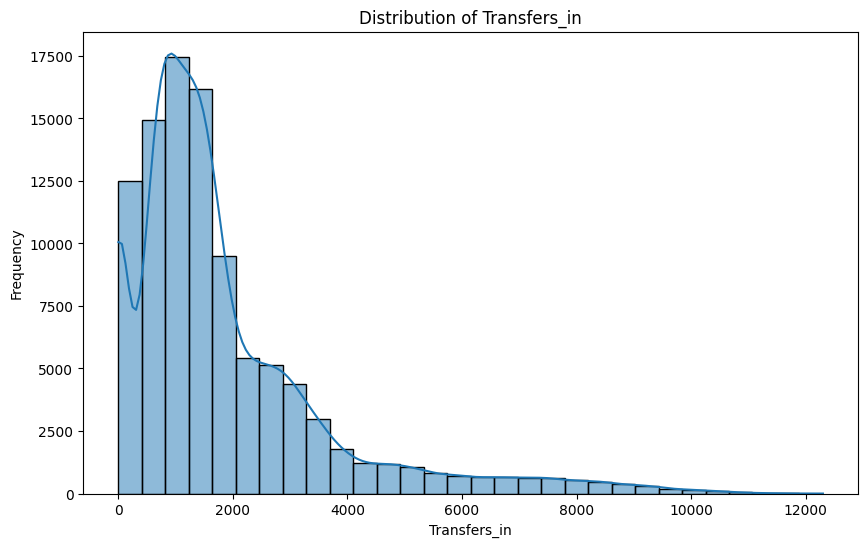



Trn_max
Mean: 63534.88
Standard Deviation: 93651.9
Min: 0.0
Q1: 12936.34
Median: 30526.81
Q3: 60482.37
Max: 584597.68


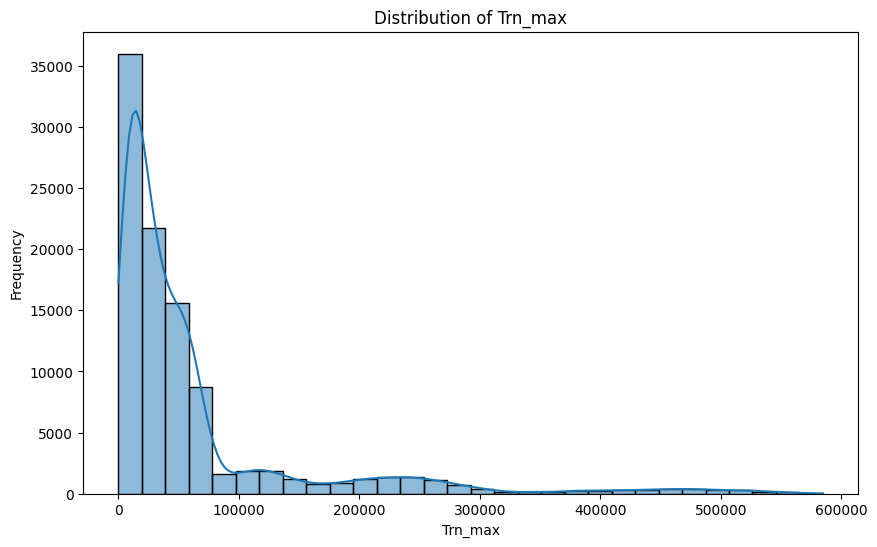



Balance
Mean: 4028.05
Standard Deviation: 6641.77
Min: -453.0
Q1: 889.0
Median: 1853.0
Q3: 3673.0
Max: 45123.0


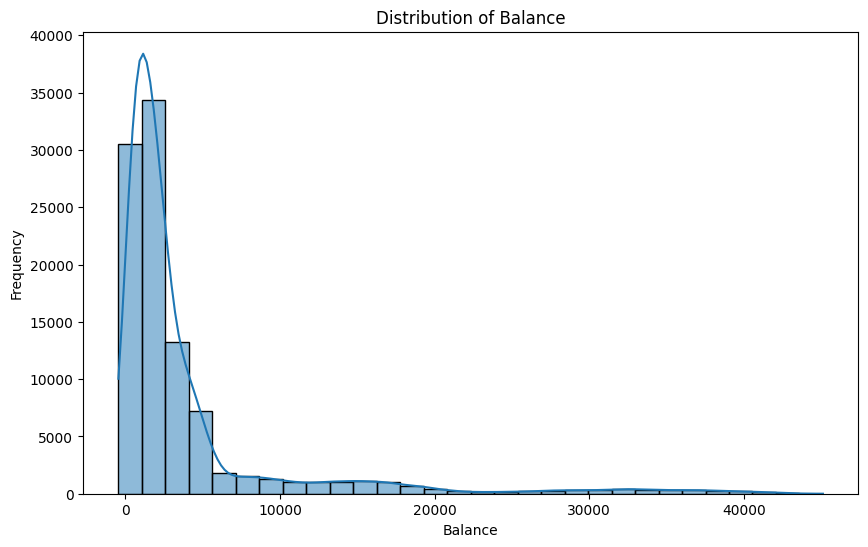



Loan
Mean: 1827.55
Standard Deviation: 2671.31
Min: 0.0
Q1: 0.0
Median: 1038.77
Q3: 2504.75
Max: 25458.63


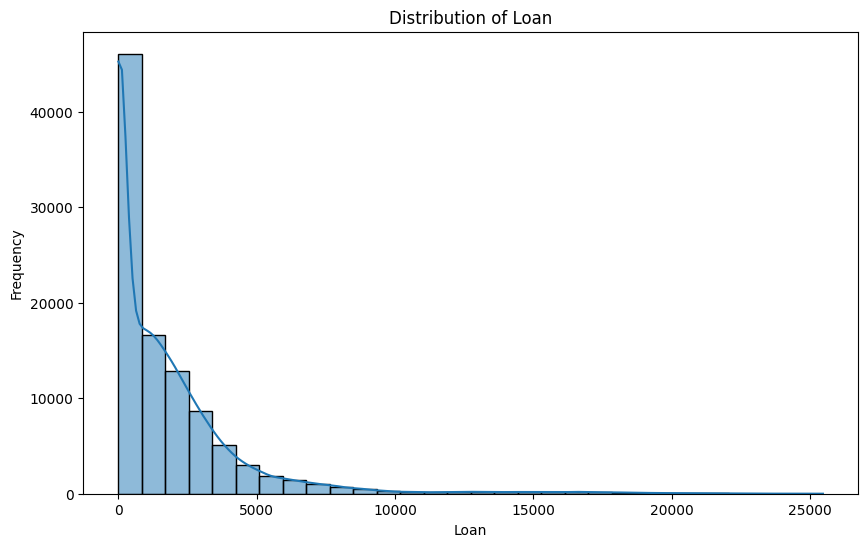



Payments
Mean: 107522.96
Standard Deviation: 153547.58
Min: 0.0
Q1: 23853.77
Median: 55004.31
Q3: 116347.17
Max: 1144276.92


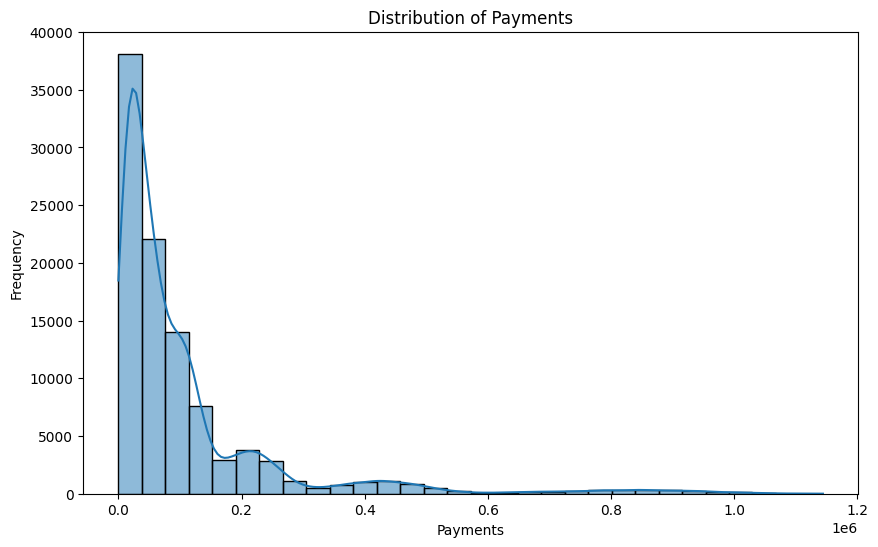



Inc_Past_avg
Mean: 1948.86
Standard Deviation: 1929.68
Min: 0.0
Q1: 620.86
Median: 1438.71
Q3: 2640.33
Max: 16417.57


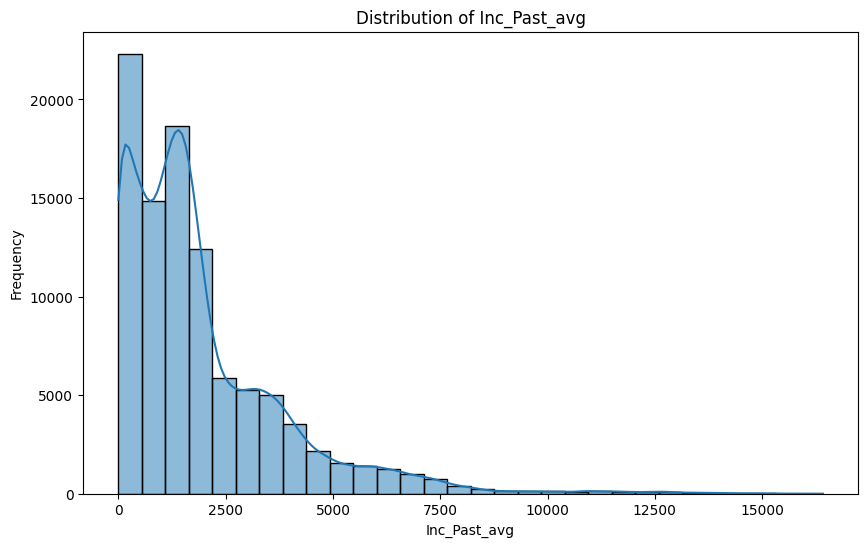



Inc_Past_max
Mean: 2517.08
Standard Deviation: 2355.49
Min: 0.0
Q1: 927.72
Median: 1865.48
Q3: 3424.14
Max: 17199.72


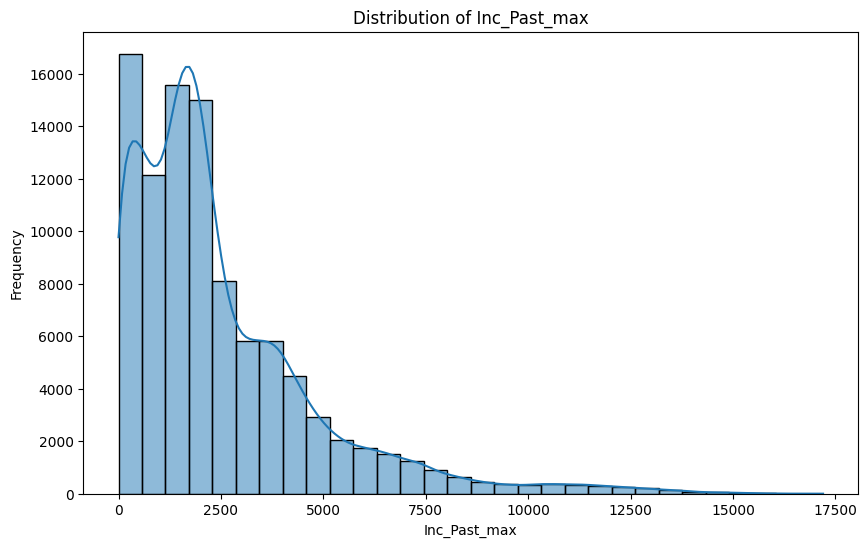



Tot_in
Mean: 62684.79
Standard Deviation: 106840.25
Min: 0.0
Q1: 12403.89
Median: 29976.26
Q3: 63705.68
Max: 743784.37


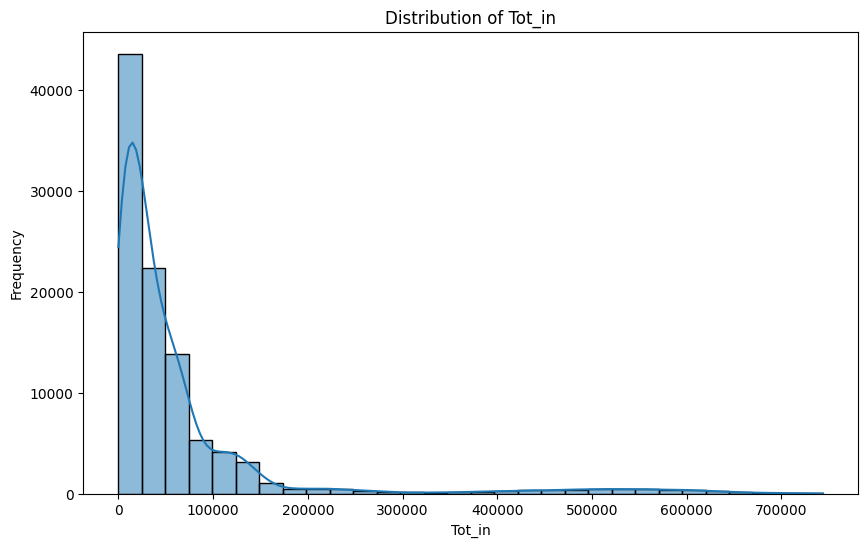



Bal_Cur
Mean: 4124.27
Standard Deviation: 6693.33
Min: 0.0
Q1: 401.01
Median: 2315.29
Q3: 4860.95
Max: 57486.71


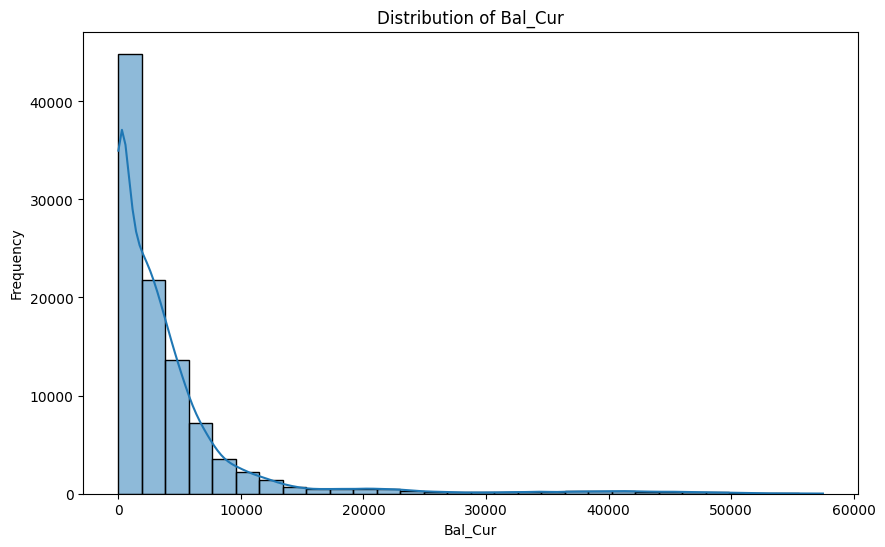



Loan_Cnt
Mean: 0.88
Standard Deviation: 1.81
Min: 0.0
Q1: 0.0
Median: 0.0
Q3: 1.0
Max: 14.0


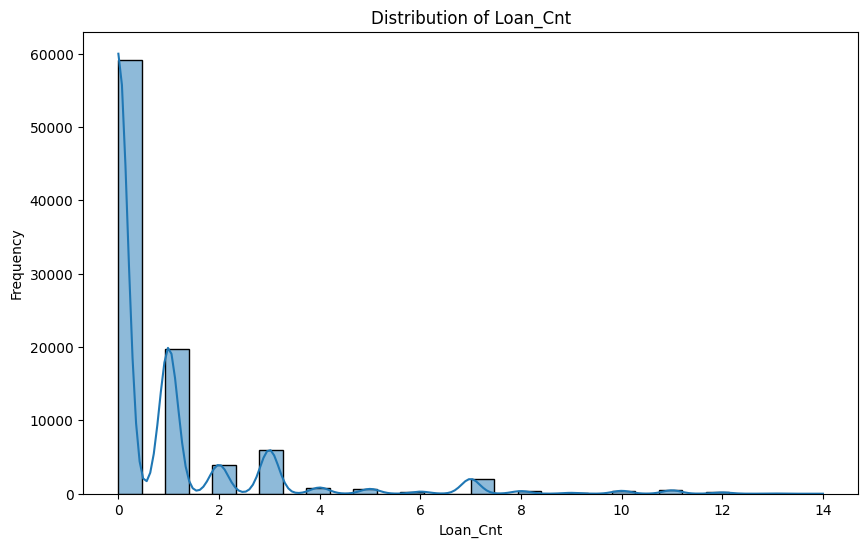

In [8]:
for column in df:
    mean=df[column].mean().round(2)
    st_dev=df[column].std().round(2)
    min=df[column].min().round(2)
    Q1=df[column].quantile(0.25).round(2)
    median=df[column].median().round(2)
    Q3=df[column].quantile(0.75).round(2)
    max=df[column].max().round(2)
    
    print(column)
    print(f"Mean: {mean}")
    print(f"Standard Deviation: {st_dev}")
    print(f"Min: {min}")    
    print(f"Q1: {Q1}")
    print(f"Median: {median}")
    print(f"Q3: {Q3}")
    print(f"Max: {max}")

    plt.figure(figsize=(10,6))
    sns.histplot(df[column], bins=30, kde=True)
    plt.title(f'Distribution of {column}')
    plt.xlabel(column)
    plt.ylabel('Frequency')
    plt.show()

    print("\n")

All variables are right skewed (positive skew, Mean > Median) and have a fairly high standard deviation (distance from the mean), from which we can assume that the data contains outliers.

When the distribution is this asymmetric, statistics such as the mean do not describe client behavior correctly and the median can be considered a better measure.

The dependent variable is defined in the range from 200 to 10,000 GEL. The 'Balance' column also has negative values, which points to an overdraft. It is also worth noting that most clients do not have a loan.

Look at the share of outliers in the variables

In [9]:
def outliers_share(df):
    results=[]
    cols=df.select_dtypes(include=['number']).columns
    for feat in cols:
        q1=df[feat].quantile(0.25)
        q3=df[feat].quantile(0.75)
        iqr=q3-q1
        lower=q1-1.5*iqr
        upper=q3+1.5*iqr
        out=((df[feat]<lower)|(df[feat]>upper)).sum()
        out_l=(df[feat]<lower).sum()
        out_u=(df[feat]>upper).sum()
        share=(out/len(df))*100
        results.append({
        'Feature': feat,
        'Outlier_Percentage': round(share,2),
        'Lower Bound': lower.round(0),
        'Lower Outliers': out_l,
        'Upper Bound': upper.round(0),
        'Upper Outliers': out_u
        })
    return pd.DataFrame(results).sort_values('Outlier_Percentage',ascending=False)

In [10]:
outliers_share(df)

,Feature,Outlier_Percentage,Lower Bound,Lower Outliers,Upper Bound,Upper Outliers
2,Liab_Tot,13.62,-37077.0,0,73219.0,13622
13,Trn_max,12.76,-58383.0,0,131801.0,12762
14,Balance,12.12,-3287.0,0,7849.0,12121
8,Transactions,11.97,-8880.0,0,20855.0,11967
9,Salary,11.20,-1300.0,0,3996.0,11205
21,Loan_Cnt,11.15,-2.0,0,2.0,11146
3,Inc_in,10.67,-1545.0,0,5574.0,10667
11,Acct_Trns,9.33,-8901.0,0,20897.0,9334
16,Payments,9.25,-114886.0,0,255087.0,9251
6,Min_transfer_In,8.47,-1687.0,0,5178.0,8467


Given the distribution of the variables, it is natural that we only have upper outliers.

In general, there are two types of outliers:

1) Univariate outliers: a value in one specific variable that is separated from the other values (an extreme value). This is the analysis we just did.

There are also:

2) Multivariate outliers: observations that differ from normal behavior in combination (not in one specific variable). There are various ML algorithms for finding such outliers, for example Isolation Forest. However, this kind of analysis requires a long and detailed investigation to establish how anomalous the detected outliers really are. That is why we will not do it this time.

Outliers can be measured with different methods, but the IQR method is one of the most widely used and it is the one we used here as well. Note that if the distribution is not normal, we can use the mean +/- 3 sigma, which guarantees that at least 88.89% of the data falls into this interval; for a normal distribution it is 99.7%.

When we use linear regression, both outliers and a skewed distribution clearly need proper handling.

In tree-based models, outliers in the independent variables are generally not a similar problem, but if the dependent variable has outliers they must be handled because of the large residuals.

The analysis so far also suggests that trying a log transformation in the model training part would be logical. (The dependent variable is skewed and 5.76% of the data are outliers)

Analyze the share of zeros in the variables

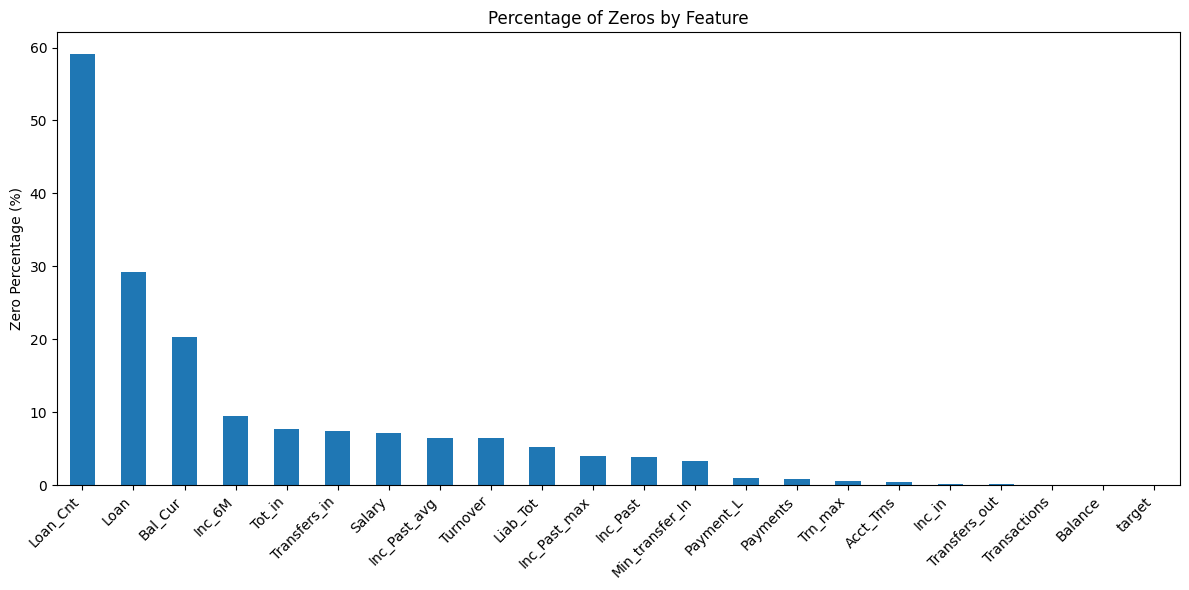

In [11]:
zero_percentages = (df == 0).mean() * 100
plt.figure(figsize=(12, 6))
zero_percentages.sort_values(ascending=False).plot(kind='bar')
plt.title('Percentage of Zeros by Feature')
plt.ylabel('Zero Percentage (%)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

Most clients do not have a loan

Compare the means of the dependent variable for zero and non-zero values of the variables


Mean Target Comparison:
            Feature  Zero_Mean  NonZero_Mean  Difference
2            Inc_in     629.40       2543.90     1914.50
3     Transfers_out     746.79       2543.66     1796.87
7      Transactions     750.31       2542.97     1792.66
15         Payments     784.03       2556.75     1772.72
10        Acct_Trns     813.14       2550.09     1736.95
17     Inc_Past_max    1029.86       2604.08     1574.22
18           Tot_in    1174.77       2655.24     1480.47
6          Turnover    1174.91       2635.83     1460.91
5   Min_transfer_In    1172.33       2588.73     1416.40
19          Bal_Cur    1595.77       2782.13     1186.36
0          Inc_Past    1426.68       2587.05     1160.37
1          Liab_Tot    1544.23       2596.79     1052.56
9            Inc_6M    1779.34       2621.50      842.16
14             Loan    2075.80       2734.20      658.40
11     Transfers_in    2118.05       2575.47      457.41
4         Payment_L    2209.69       2545.15      335.45
8     

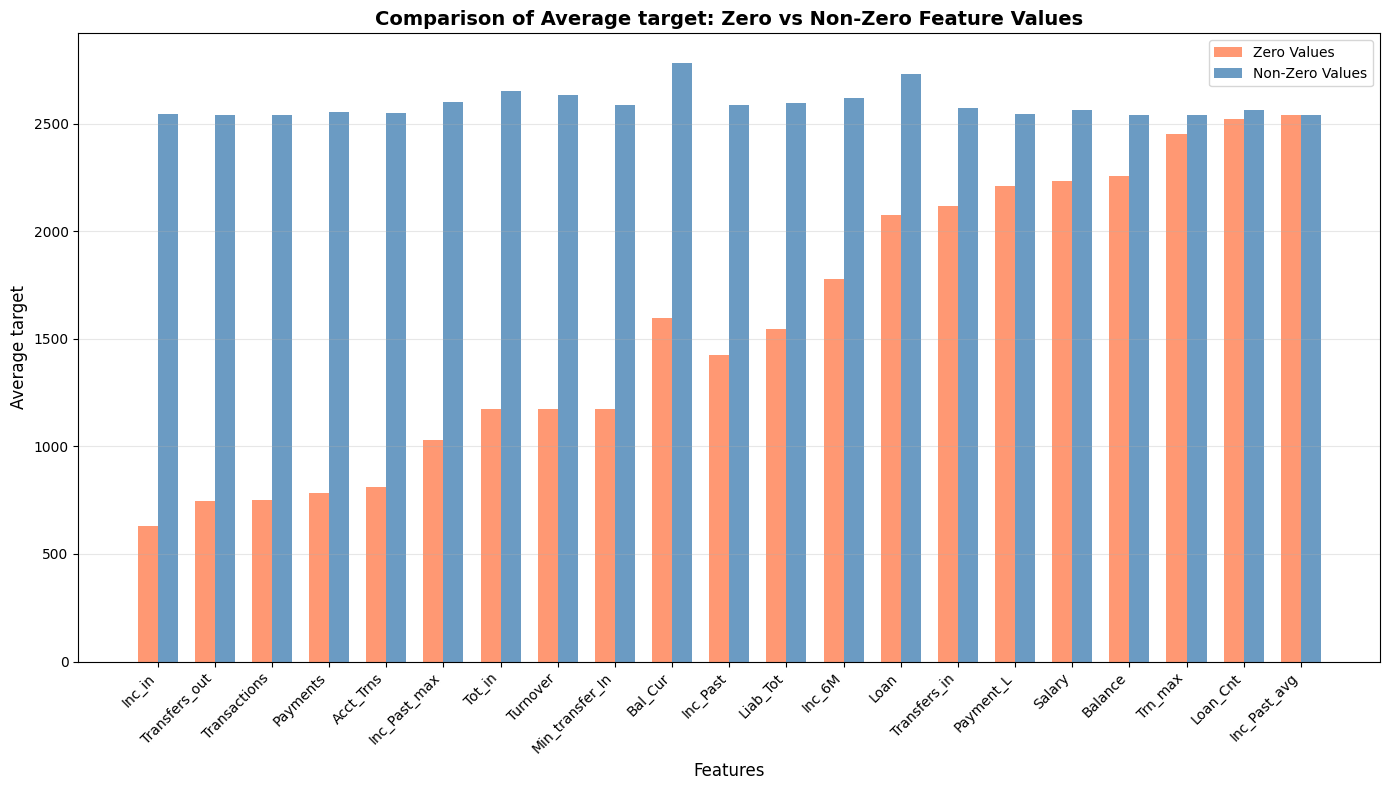

In [12]:
target='target'
features_with_zeros = []
for column in df.columns:
    if column != target and (df[column] == 0).any():
        features_with_zeros.append(column)

mean_diffs = []
for feature in features_with_zeros:
    zero_mean = df[df[feature] == 0][target].mean()
    non_zero_mean = df[df[feature] != 0][target].mean()
    mean_diffs.append({
        'Feature': feature,
        'Zero_Mean': zero_mean,
        'NonZero_Mean': non_zero_mean,
        'Difference': non_zero_mean - zero_mean
    })

diff_df = pd.DataFrame(mean_diffs).sort_values('Difference', ascending=False)

print("\nMean Target Comparison:")
print(diff_df.round(2))

fig, ax = plt.subplots(figsize=(14, 8))
x = np.arange(len(diff_df))
width = 0.35
bars1 = ax.bar(x - width/2, diff_df['Zero_Mean'], width, label='Zero Values', color='coral', alpha=0.8)
bars2 = ax.bar(x + width/2, diff_df['NonZero_Mean'], width, label='Non-Zero Values', color='steelblue', alpha=0.8)
ax.set_xlabel('Features', fontsize=12)
ax.set_ylabel(f'Average {target}', fontsize=12)
ax.set_title(f'Comparison of Average {target}: Zero vs Non-Zero Feature Values', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(diff_df['Feature'], rotation=45, ha='right')
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

Here we can see that for zero values of the variables the mean of the dependent variable is practically always lower than for non-zero values, which is logical, because a person with frequent non-zero transactional data should normally have a higher income too.

In some variables the share of zeros is so low that comparing means computed on that many records may be a bit unreliable (in general a group should hold at least 5% for its behavior to be statistically assessable), but this analysis is fine for seeing the general trend.

The last variable, the client's past average income, is interesting: the target is almost identical for its zero and non-zero values. An expert opinion would be interesting here. Since I do not know exactly how this variable is calculated, we can assume that it refers to the segment whose declared income is simply not credited to the card, and that is why it is zero.

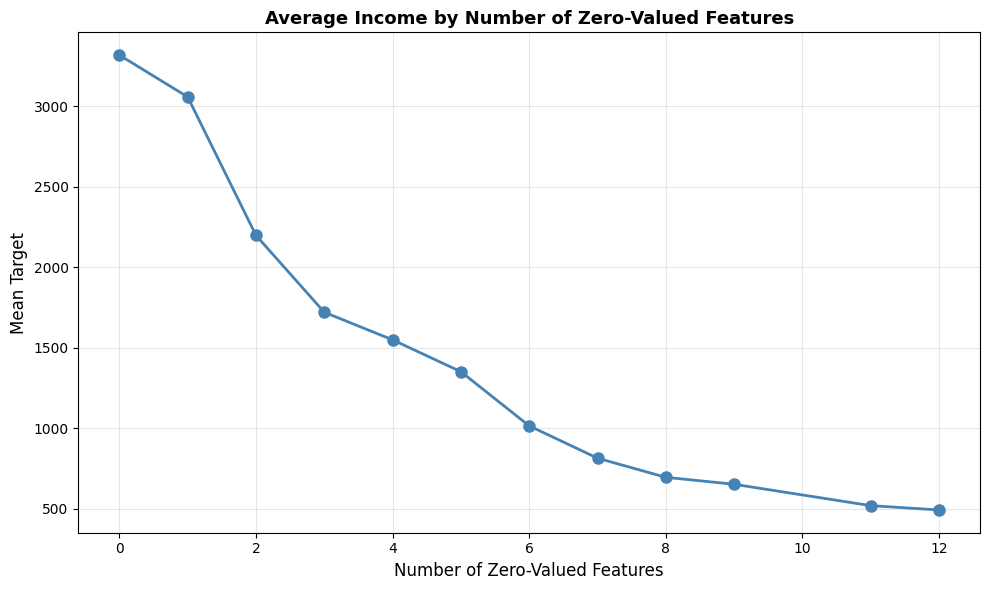

In [13]:
features = [col for col in df.columns if col != 'target']
df['zero_count'] = (df[features] == 0).sum(axis=1)

zero_count_analysis = df.groupby('zero_count')['target'].agg(['mean', 'median', 'count']).reset_index()

plt.figure(figsize=(10, 6))
plt.plot(zero_count_analysis['zero_count'], zero_count_analysis['mean'], marker='o', linewidth=2, markersize=8, color='steelblue')
plt.xlabel('Number of Zero-Valued Features', fontsize=12)
plt.ylabel('Mean Target', fontsize=12)
plt.title('Average Income by Number of Zero-Valued Features', fontsize=13, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

df.drop('zero_count', axis=1, inplace=True)

The more variables with a value of zero we combine, the lower the income levels we get. Variables with a zero value reflect less financial activity, which is typical of low income clients. (The picture is identical if we replace the means with the median)

Create new meaningful (domain-driven) variables:

* Client's past average income / client's liabilities (Inc_Past_avg/Liab_Tot)

* Salary / monthly payment (Salary/Payment_L)

* Amounts received on the account / outgoing transfers from the account (Transfers_in/Acct_Trns)

* Total incoming payments on the account / client's liabilities (Tot_in/Liab_Tot)

If we knew the exact calculation logic of each variable, it would be possible to derive even more informative variables

In [14]:
eps=1e-6
df['income_avg_liability_ratio']=df['Inc_Past_avg']/(df['Liab_Tot']+eps)
df['salary_payment_ratio']=df['Salary']/(df['Payment_L']+eps)
df['transfers_in_out_ratio']=df['Transfers_in']/(df['Acct_Trns']+eps)
df['total_in_liability_ratio']=df['Tot_in']/(df['Liab_Tot']+eps)

Multivariate Analysis

Since all variables are continuous, it is enough to measure only the linear relationship between them (Pearson's correlation). Using other types of correlation makes no sense in this case.

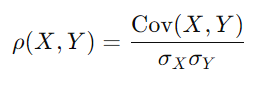

In [15]:
corr_matrix=df.corr()
corr_matrix.style.background_gradient(cmap='coolwarm').format(precision=2)

,target,Inc_Past,Liab_Tot,Inc_in,Transfers_out,Payment_L,Min_transfer_In,Turnover,Transactions,Salary,Inc_6M,Acct_Trns,Transfers_in,Trn_max,Balance,Loan,Payments,Inc_Past_avg,Inc_Past_max,Tot_in,Bal_Cur,Loan_Cnt,income_avg_liability_ratio,salary_payment_ratio,transfers_in_out_ratio,total_in_liability_ratio
target,1.00,0.54,0.56,0.74,0.49,0.52,0.76,0.63,0.50,0.64,0.62,0.37,0.64,0.00,-0.00,0.41,0.47,-0.00,0.61,0.40,0.39,0.10,-0.09,0.03,-0.06,-0.02
Inc_Past,0.54,1.00,0.40,0.45,0.34,0.40,0.47,0.71,0.34,0.30,0.32,0.24,0.32,0.00,-0.00,0.31,0.32,0.00,0.68,0.25,0.21,0.06,-0.06,0.01,-0.04,-0.03
Liab_Tot,0.56,0.40,1.00,0.51,0.45,0.65,0.47,0.51,0.45,0.39,0.37,0.33,0.41,0.00,0.00,0.45,0.44,-0.00,0.46,0.35,0.24,0.02,-0.11,-0.04,-0.03,-0.07
Inc_in,0.74,0.45,0.51,1.00,0.48,0.42,0.73,0.56,0.49,0.63,0.60,0.38,0.61,0.00,0.00,0.39,0.47,0.00,0.55,0.41,0.43,0.07,-0.07,0.06,-0.04,-0.02
Transfers_out,0.49,0.34,0.45,0.48,1.00,0.36,0.41,0.40,0.79,0.37,0.34,0.72,0.37,0.01,-0.00,0.33,0.80,0.00,0.40,0.75,0.48,0.02,-0.05,0.03,-0.04,0.06
Payment_L,0.52,0.40,0.65,0.42,0.36,1.00,0.39,0.49,0.37,0.29,0.28,0.24,0.32,0.01,0.00,0.41,0.35,-0.00,0.43,0.27,0.16,0.03,-0.08,-0.08,-0.03,-0.05
Min_transfer_In,0.76,0.47,0.47,0.73,0.41,0.39,1.00,0.57,0.42,0.73,0.73,0.29,0.73,0.00,0.00,0.37,0.39,-0.00,0.56,0.32,0.39,0.12,-0.07,0.05,-0.05,-0.02
Turnover,0.63,0.71,0.51,0.56,0.40,0.49,0.57,1.00,0.39,0.39,0.41,0.27,0.42,0.00,-0.00,0.40,0.37,0.00,0.75,0.29,0.25,0.08,-0.07,-0.00,-0.04,-0.03
Transactions,0.50,0.34,0.45,0.49,0.79,0.37,0.42,0.39,1.00,0.39,0.36,0.77,0.39,0.00,-0.00,0.33,0.84,-0.00,0.40,0.79,0.51,0.03,-0.05,0.04,-0.04,0.07
Salary,0.64,0.30,0.39,0.63,0.37,0.29,0.73,0.39,0.39,1.00,0.79,0.27,0.82,0.00,0.00,0.30,0.37,-0.01,0.39,0.32,0.40,0.10,-0.05,0.09,-0.04,-0.01


Treat as high correlation every linear relationship whose absolute value is greater than or equal to 70%, and look at such pairs

In [16]:
corr_matrix_no_target = df.drop('target', axis=1).corr()
threshold = 0.7
upper_triangle = corr_matrix_no_target.where(np.triu(np.ones(corr_matrix_no_target.shape), k=1).astype(bool))

high_corr_pairs = []
for column in upper_triangle.columns:
    for index in upper_triangle.index:
        corr_value = upper_triangle.loc[index, column]
        if pd.notna(corr_value) and abs(corr_value) >= threshold:
            high_corr_pairs.append({
                'Feature_1': index,
                'Feature_2': column,
                'Correlation': round(corr_value, 3)
            })

high_corr_df = pd.DataFrame(high_corr_pairs).sort_values('Correlation', ascending=False, key=abs)
print(f"Feature pairs with absolute correlation >= {threshold}:\n")
print(high_corr_df)

Feature pairs with absolute correlation >= 0.7:

          Feature_1        Feature_2  Correlation
12     Transactions         Payments        0.839
9            Salary     Transfers_in        0.819
11    Transfers_out         Payments        0.803
18         Payments           Tot_in        0.801
10           Inc_6M     Transfers_in        0.793
5            Salary           Inc_6M        0.793
17        Acct_Trns           Tot_in        0.789
2     Transfers_out     Transactions        0.785
16     Transactions           Tot_in        0.785
13        Acct_Trns         Payments        0.777
7      Transactions        Acct_Trns        0.767
15    Transfers_out           Tot_in        0.755
14         Turnover     Inc_Past_max        0.749
4   Min_transfer_In           Inc_6M        0.732
0            Inc_in  Min_transfer_In        0.732
8   Min_transfer_In     Transfers_in        0.726
3   Min_transfer_In           Salary        0.726
6     Transfers_out        Acct_Trns        0.716
1

The strongest linear relationship turned out to be between payments and transactions from the account, which was expected from the meaning of the variables as well. In general there is a strong relationship between the transactional variables and liabilities, and between income and transactions, which also makes sense. The correlation matrix shows that the variables have a multicollinearity problem.

Measure multicollinearity with the variance inflation factor

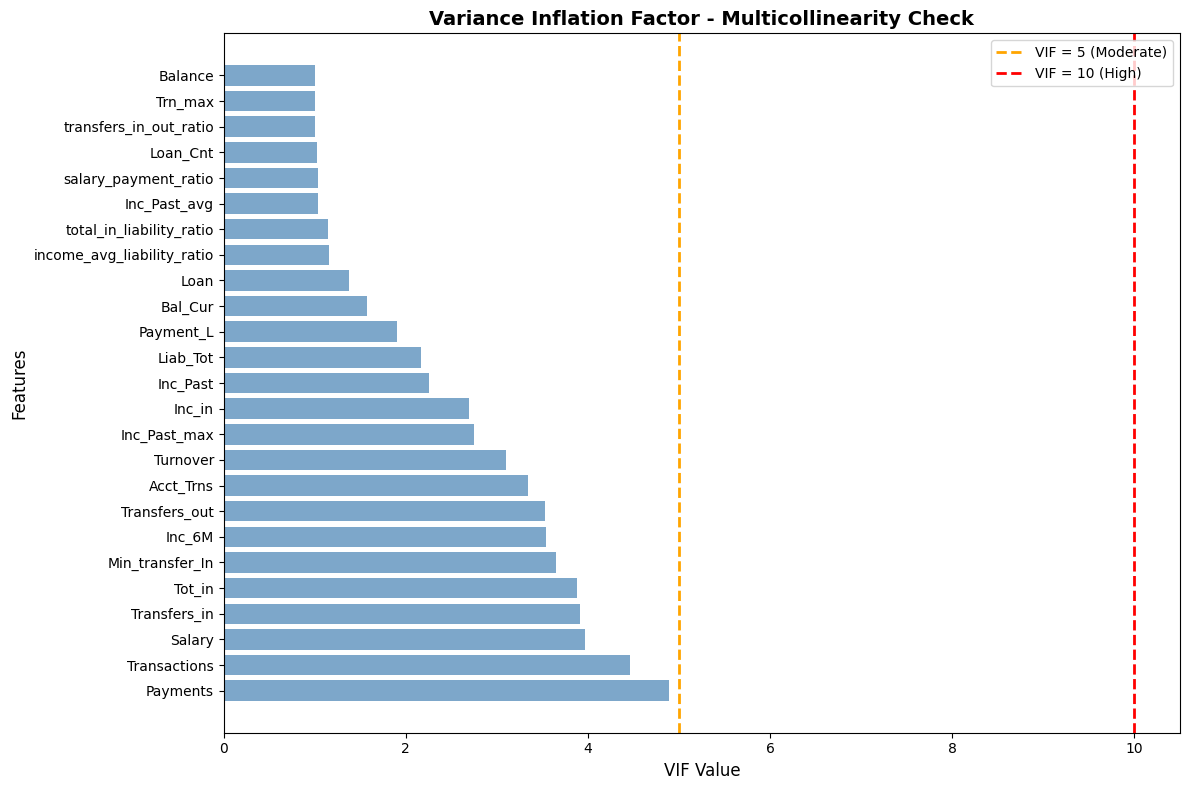

In [17]:
X = df.drop('target', axis=1)
X_clean = X.dropna()
X_with_const = add_constant(X_clean)

vif_data = pd.DataFrame()
vif_data['Feature'] = X_with_const.columns
vif_data['VIF'] = [variance_inflation_factor(X_with_const.values, i) for i in range(X_with_const.shape[1])]

vif_data = vif_data[vif_data['Feature'] != 'const'].sort_values('VIF', ascending=False).reset_index(drop=True)

plt.figure(figsize=(12, 8))
plt.barh(vif_data['Feature'], vif_data['VIF'], color='steelblue', alpha=0.7)
plt.axvline(x=5, color='orange', linestyle='--', linewidth=2, label='VIF = 5 (Moderate)')
plt.axvline(x=10, color='red', linestyle='--', linewidth=2, label='VIF = 10 (High)')
plt.xlabel('VIF Value', fontsize=12)
plt.ylabel('Features', fontsize=12)
plt.title('Variance Inflation Factor - Multicollinearity Check', fontsize=14, fontweight='bold')
plt.legend()
plt.tight_layout()
plt.show()

Look at the linear relationship of the variables with the dependent variable

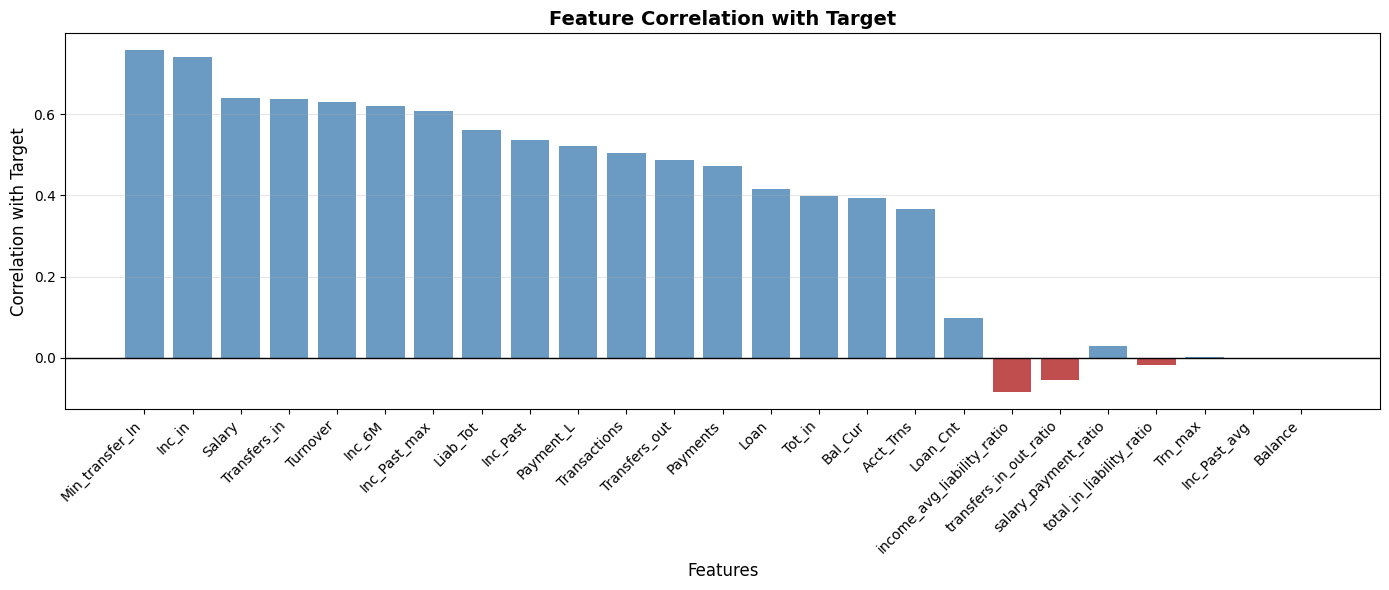

In [18]:
target_corr = df.corr()['target'].drop('target')

corr_df = (
    target_corr
    .to_frame('correlation')
    .assign(abs_corr=lambda x: x['correlation'].abs())
    .sort_values('abs_corr', ascending=False)
)

plt.figure(figsize=(14, 6))
colors = corr_df['correlation'].apply(
    lambda x: 'firebrick' if x < 0 else 'steelblue'
)
plt.bar(corr_df.index, corr_df['correlation'], color=colors, alpha=0.8)
plt.axhline(0, color='black', linewidth=1)
plt.ylabel('Correlation with Target', fontsize=12)
plt.xlabel('Features', fontsize=12)
plt.title('Feature Correlation with Target', fontsize=14, fontweight='bold')
plt.xticks(rotation=45, ha='right') 
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

The bar chart shows the variables with the strongest linear relationship with the target variable.

Two factors are important to keep in mind here:

1) When we build the linear regression, we will have a different pipeline compared to the tree-based models. In linear models we cannot use variables that are highly correlated with each other, because the independent variables have to be independent of each other too. With linear regression it is easy to decide which variable to keep in the model and which one to drop, because the variable with a higher correlation with the dependent variable is the stronger predictor (the stronger variable). Also, the analysis of the variables showed that the derived variables have neither a high correlation with the original variables nor an alarming VIF, so we will keep these variables for use in the model.

2) The same interpretation is wrong for tree-based models, because they are nonlinear and a variable that is more linearly related to the target will not necessarily be stronger in the model (the model looks at the variables nonlinearly). Also, highly correlated variables are not a similar problem in tree-based models and dropping them is not required (although it should be noted that they affect feature importance).

For additional insights we can also build a pairwise relationship heatmap.

## Data Preprocessing

Before starting the data preparation part, we have to separate the train and test sets from each other in order to avoid data leakage

In [19]:
RANDOM_STATE = 42
X = df.drop('target', axis=1)
y = df['target']

In [20]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

In this case we set aside a random 20% as the test set, but it should be noted that when working on real projects we often use a second test set as well, made of the most recent period, to get a better view of how the model will work in the future.

1) Impute the data with KNN imputation. It is important to use standardization here, so that the data is on a comparable scale and the algorithm works correctly.

2) When working with linear regression, outliers are a problem and need proper handling. Outlier values of a variable are a problem for gradient descent (for finding the right coefficients), and handling them also matters in production, to avoid excessively large values of the dependent variable.

    Tree-based models generally cope with outliers and leaving them in is not a problem (this is not about the dependent variable, where outliers must be handled to get a model with better results), but in this case we will cap the outliers in all variables, because this is useful for linear regression and, in addition, having no outliers in the data matters for the KNN algorithm to work correctly and impute the missing values as accurately as possible.

We cap the outliers with the high threshold of the IQR method. We write two independent pipelines, one for linear regression and the other for tree-based models.

In [21]:
def fit_iqr_capper(X_train: pd.DataFrame,
                   y_train: pd.Series,
                   multiplier: float = 1.5):
    """
    Fit IQR-based capping thresholds on TRAIN only (for X and y).
    Stores per-feature lower/upper bounds + y bounds to reuse on test later.
    """
    if not isinstance(X_train, pd.DataFrame):
        raise TypeError("X_train must be a pandas DataFrame (so we can store per-column thresholds).")
    if not isinstance(y_train, (pd.Series, pd.DataFrame)):
        raise TypeError("y_train must be a pandas Series.")

    bounds = {"X": {}, "y": None, "multiplier": multiplier}

    # Feature bounds
    for col in X_train.columns:
        s = X_train[col].astype(float)
        q1 = s.quantile(0.25)
        q3 = s.quantile(0.75)
        iqr = q3 - q1
        lower = q1 - multiplier * iqr
        upper = q3 + multiplier * iqr
        bounds["X"][col] = (lower, upper)

    # Target bounds
    y = y_train.astype(float)
    q1 = y.quantile(0.25)
    q3 = y.quantile(0.75)
    iqr = q3 - q1
    y_lower = q1 - multiplier * iqr
    y_upper = q3 + multiplier * iqr
    bounds["y"] = (y_lower, y_upper)

    return bounds


def apply_iqr_capping_X(X: pd.DataFrame, bounds: dict) -> pd.DataFrame:
    """
    Apply pre-fitted IQR bounds to cap X (train or test).
    """
    Xc = X.copy()
    for col, (lower, upper) in bounds["X"].items():
        if col in Xc.columns and np.isfinite(lower) and np.isfinite(upper):
            Xc[col] = Xc[col].clip(lower=lower, upper=upper)
    return Xc


def apply_iqr_capping_y(y: pd.Series, bounds: dict) -> pd.Series:
    """
    Apply pre-fitted IQR bounds to cap y (train or test y if you ever need it).
    """
    y_lower, y_upper = bounds["y"]
    if np.isfinite(y_lower) and np.isfinite(y_upper):
        return y.astype(float).clip(lower=y_lower, upper=y_upper)
    return y.astype(float)


class ScaleKNNImputeBack:
    """
    Fit on TRAIN:
      - StandardScaler on X_train
      - KNNImputer(k=5) on scaled X_train
    Transform on any X:
      - scale
      - impute
      - inverse scale back to original units
    """
    def __init__(self, n_neighbors: int = 5):
        self.n_neighbors = n_neighbors
        self.scaler = StandardScaler()
        self.imputer = KNNImputer(n_neighbors=n_neighbors)
        self.feature_names_in_ = None

    def fit(self, X_train: pd.DataFrame):
        if not isinstance(X_train, pd.DataFrame):
            raise TypeError("X_train must be a pandas DataFrame.")
        self.feature_names_in_ = X_train.columns.tolist()

        X_scaled = self.scaler.fit_transform(X_train)   # fit scaler on train only
        self.imputer.fit(X_scaled)                      # fit imputer on scaled train
        return self

    def transform(self, X: pd.DataFrame) -> pd.DataFrame:
        if not isinstance(X, pd.DataFrame):
            raise TypeError("X must be a pandas DataFrame.")
        X = X[self.feature_names_in_].copy()

        X_scaled = self.scaler.transform(X)
        X_imputed_scaled = self.imputer.transform(X_scaled)
        X_imputed = self.scaler.inverse_transform(X_imputed_scaled)

        return pd.DataFrame(X_imputed, columns=self.feature_names_in_, index=X.index)


def fit_train_preprocessing(X_train: pd.DataFrame,
                            y_train: pd.Series,
                            iqr_multiplier: float = 1.5,
                            knn_k: int = 5):
    """
    Fit everything using TRAIN only:
      - IQR bounds for capping X and y (RAW train)
      - Scale+KNN imputer (on capped X_train)
      - SECOND capping after imputation with NEW boundaries (fit on imputed train)
    Returns fitted objects to reuse on test later.
    """
    # 1) Fit IQR capping thresholds on raw train
    cap_bounds_pre = fit_iqr_capper(X_train, y_train, multiplier=iqr_multiplier)

    # 2) Apply first capping to TRAIN (X and y)
    X_train_capped = apply_iqr_capping_X(X_train, cap_bounds_pre)
    y_train_capped = apply_iqr_capping_y(y_train, cap_bounds_pre)

    # 3) Fit scaler + KNN on first-capped TRAIN X
    impute_pipe = ScaleKNNImputeBack(n_neighbors=knn_k).fit(X_train_capped)

    # 4) Impute TRAIN X (back in original units)
    X_train_imputed = impute_pipe.transform(X_train_capped)

    # 5) Fit SECOND IQR boundaries on TRAIN *after imputation* (recalculate boundaries)
    cap_bounds_post = {"X": {}, "multiplier": iqr_multiplier}
    for col in X_train_imputed.columns:
        s = X_train_imputed[col].astype(float)
        q1 = s.quantile(0.25)
        q3 = s.quantile(0.75)
        iqr = q3 - q1
        lower = q1 - iqr_multiplier * iqr
        upper = q3 + iqr_multiplier * iqr
        cap_bounds_post["X"][col] = (lower, upper)

    # 6) Apply SECOND capping to the imputed TRAIN X
    X_train_final = apply_iqr_capping_X(X_train_imputed, cap_bounds_post)

    return {
        "cap_bounds": cap_bounds_pre,            # reuse for test FIRST capping
        "cap_bounds_post": cap_bounds_post,      # reuse for test SECOND capping (after imputation)
        "impute_pipe": impute_pipe,              # reuse for test imputation later
        "X_train_final": X_train_final,
        "y_train_capped": y_train_capped
    }


def transform_test_preprocessing(X_test: pd.DataFrame,
                                 cap_bounds: dict,
                                 cap_bounds_post: dict,
                                 impute_pipe: ScaleKNNImputeBack) -> pd.DataFrame:
    """
    Apply TRAIN-fitted preprocessing to TEST:
      - cap using train-fitted IQR thresholds (PRE)
      - scale -> KNN impute -> inverse scale (back to original units)
      - cap AGAIN using train-fitted IQR thresholds (POST, fitted on imputed train)
    """
    X_test_capped = apply_iqr_capping_X(X_test, cap_bounds)
    X_test_imputed = impute_pipe.transform(X_test_capped)
    X_test_final = apply_iqr_capping_X(X_test_imputed, cap_bounds_post)
    return X_test_final

Use K=5 in the KNN algorithm. It is important that we do everything on the training data and only apply the final results to the test set, both in the imputation part and in the outlier handling part, which is how we avoid data leakage.

In [22]:
fitted = fit_train_preprocessing(X_train, y_train, iqr_multiplier=1.5, knn_k=5)
X_train = fitted["X_train_final"]
y_train = fitted["y_train_capped"]

X_test = transform_test_preprocessing(X_test, fitted["cap_bounds"], fitted["cap_bounds_post"], fitted["impute_pipe"])
y_test = apply_iqr_capping_y(y_test, fitted["cap_bounds"])

Make sure there are no outliers left in the data

In [23]:
outliers_share(X_train)

,Feature,Outlier_Percentage,Lower Bound,Lower Outliers,Upper Bound,Upper Outliers
0,Inc_Past,0.0,-1616.0,0,5038.0,0
1,Liab_Tot,0.0,-36699.0,0,72963.0,0
2,Inc_in,0.0,-1543.0,0,5572.0,0
3,Transfers_out,0.0,-10750.0,0,23338.0,0
4,Payment_L,0.0,-1259.0,0,3207.0,0
5,Min_transfer_In,0.0,-1700.0,0,5195.0,0
6,Turnover,0.0,-2369.0,0,6198.0,0
7,Transactions,0.0,-8850.0,0,20813.0,0
8,Salary,0.0,-1310.0,0,4010.0,0
9,Inc_6M,0.0,-1595.0,0,4021.0,0


Save the original training and test data for the different models

In [24]:
X_TRAIN=X_train
X_TEST=X_test
Y_TRAIN=y_train
Y_TEST=y_test

For linear regression, drop the highly correlated variables. We had already found such pairs, but we compute them again with a somewhat less strict threshold and using the training data only.

In [25]:
threshold = 0.76 # drop the variables with a correlation above 75%
target_corr = X_train.corrwith(y_train).abs()
corr = X_train.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))

pairs = (
    upper.stack()
         .reset_index()
         .rename(columns={"level_0": "Feature_1", "level_1": "Feature_2", 0: "Abs_Corr"})
)
pairs = pairs[pairs["Abs_Corr"] >= threshold].sort_values("Abs_Corr", ascending=False)

features_to_keep = set(X_train.columns)

for _, row in pairs.iterrows():
    f1, f2 = row["Feature_1"], row["Feature_2"]

    if f1 not in features_to_keep or f2 not in features_to_keep:
        continue

    if target_corr[f1] < target_corr[f2]:
        features_to_keep.discard(f1)
    else:
        features_to_keep.discard(f2)

features_to_drop = sorted(set(X_train.columns) - features_to_keep)

print("Features to drop:", features_to_drop)
print("Number of features to drop:", len(features_to_drop))

X_train = X_train.drop(columns=features_to_drop)
X_test = X_test.drop(columns=features_to_drop)

print("Remaining features:", X_train.shape[1])

Features to drop: ['Acct_Trns', 'Inc_6M', 'Inc_Past_max', 'Payments', 'Salary', 'Tot_in', 'Transactions']
Number of features to drop: 7
Remaining features: 18


## Modeling

Build a linear regression. Since the dataset is not large, we can first use the coefficients computed with the OLS method and look at the corresponding p-values.

In [26]:
X_train_sm = sm.add_constant(X_train) 
ols_model = sm.OLS(y_train, X_train_sm).fit()

pvals_df = pd.DataFrame({
    "feature": X_train_sm.columns,
    "p_value": ols_model.pvalues
}).sort_values("p_value")

print("\nP-values:")
print(pvals_df)
significant_features = pvals_df[pvals_df["p_value"] < 0.05]["feature"].tolist()
significant_features = [f for f in significant_features if f != "const"]
dropped_features = set(X_train.columns) - set(significant_features)
print("Dropped features:", dropped_features)

X_train = X_train[significant_features]
X_test = X_test[significant_features]


P-values:
                                               feature        p_value
Inc_in                                          Inc_in   0.000000e+00
Turnover                                      Turnover   0.000000e+00
Min_transfer_In                        Min_transfer_In   0.000000e+00
Payment_L                                    Payment_L   0.000000e+00
Transfers_in                              Transfers_in  4.539976e-203
Inc_Past                                      Inc_Past   4.468932e-88
Bal_Cur                                        Bal_Cur   1.551722e-75
Liab_Tot                                      Liab_Tot   1.616202e-66
Transfers_out                            Transfers_out   8.866207e-56
salary_payment_ratio              salary_payment_ratio   4.705117e-35
Loan                                              Loan   2.023024e-29
transfers_in_out_ratio          transfers_in_out_ratio   3.439700e-14
income_avg_liability_ratio  income_avg_liability_ratio   2.513238e-03
total_in_

We dropped the weak variables based on the p-value; these two variables had a very weak correlation with the target from the start.

Build a baseline linear regression using the scikit-learn library

In [27]:
reg = LinearRegression()
reg.fit(X_train, y_train)

y_train_pred = reg.predict(X_train)
y_test_pred  = reg.predict(X_test)

Define the functions needed for evaluation

In [28]:
def regression_metrics(y_true, y_pred):
    mape = mean_absolute_percentage_error(y_true, y_pred)
    mae  = mean_absolute_error(y_true, y_pred)
    r2   = r2_score(y_true, y_pred)
    return r2, mape, mae

def within_error_accuracy(y_true, y_pred, thresholds=(0.05, 0.10, 0.15, 0.20), eps=eps):
    denom = np.where(y_true == 0, eps, np.abs(y_true))
    rel_error = np.abs(y_true - y_pred) / denom

    return {
        f"within_{int(t*100)}%": round((rel_error <= t).mean() * 100, 2)
        for t in thresholds
    }

In [29]:
coef_df = pd.DataFrame({
    "feature": X_train.columns,
    "coefficient": reg.coef_
}).sort_values("coefficient", key=np.abs, ascending=False)

print("Intercept:", reg.intercept_)
print("\nCoefficients:")
print(coef_df)

Intercept: 8.29829937340628

Coefficients:
                       feature  coefficient
11      transfers_in_out_ratio   -82.906772
12  income_avg_liability_ratio   -50.341649
9         salary_payment_ratio    25.474576
15                    Loan_Cnt    -7.487061
13    total_in_liability_ratio     2.527616
2              Min_transfer_In     0.302584
0                       Inc_in     0.296155
3                    Payment_L     0.290251
4                 Transfers_in     0.124915
1                     Turnover     0.119424
5                     Inc_Past     0.066365
6                      Bal_Cur     0.022286
10                        Loan     0.022017
8                Transfers_out     0.011762
14                Inc_Past_avg     0.005335
7                     Liab_Tot     0.003893


In [30]:
train_metrics = regression_metrics(y_train, y_train_pred)
test_metrics  = regression_metrics(y_test, y_test_pred)

metrics_df = pd.DataFrame(
    [train_metrics, test_metrics],
    columns=["R2", "MAPE", "MAE"],
    index=["Train", "Test"]
)

print("\nRegression metrics:")
print(metrics_df)


Regression metrics:
             R2      MAPE         MAE
Train  0.740040  0.367164  635.103365
Test   0.733104  0.365817  636.667181


In [31]:
train_acc = within_error_accuracy(y_train, y_train_pred)
test_acc  = within_error_accuracy(y_test, y_test_pred)

accuracy_df = pd.DataFrame([train_acc, test_acc], index=["Train", "Test"])

print("\nWithin-error accuracy:")
print(accuracy_df)


Within-error accuracy:
       within_5%  within_10%  within_15%  within_20%
Train      12.57       24.20       34.88       44.53
Test       12.48       23.56       34.49       44.31


Look at the strength of the variables

In [32]:
feature_names = X_train.columns
scaler=StandardScaler()
X_scaled = scaler.fit_transform(X_train)
model = LinearRegression()
model.fit(X_scaled, y_train)
coefficients = model.coef_
feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': np.abs(coefficients)
}).sort_values(by='Importance', ascending=False)
print(feature_importance)

                       Feature  Importance
0                       Inc_in  461.742923
2              Min_transfer_In  453.596396
3                    Payment_L  245.985795
1                     Turnover  211.998869
4                 Transfers_in  169.821119
7                     Liab_Tot   96.169852
5                     Inc_Past   93.109436
8                Transfers_out   79.393685
6                      Bal_Cur   75.554893
9         salary_payment_ratio   57.090795
10                        Loan   40.011394
11      transfers_in_out_ratio   30.770708
12  income_avg_liability_ratio   15.873961
13    total_in_liability_ratio   14.892187
14                Inc_Past_avg    8.306712
15                    Loan_Cnt    6.430653


As mentioned at the beginning, try the log transformation and build the linear regression again

I use log1p so that values equal to 0 can be log transformed

In [33]:
X_train_log = np.log1p(X_train)
X_test_log  = np.log1p(X_test)
y_train_log = np.log1p(y_train)
y_test_log  = np.log1p(y_test)

In [34]:
reg.fit(X_train_log, y_train_log)

y_train_pred_log = reg.predict(X_train_log)
y_test_pred_log  = reg.predict(X_test_log)

y_train_pred = np.expm1(y_train_pred_log)
y_test_pred  = np.expm1(y_test_pred_log)

In [35]:
train_metrics = regression_metrics(y_train, y_train_pred)
test_metrics  = regression_metrics(y_test, y_test_pred)

metrics_df = pd.DataFrame(
    [train_metrics, test_metrics],
    columns=["R2", "MAPE", "MAE"],
    index=["Train", "Test"]
)

print("\nRegression metrics:")
print(metrics_df)


Regression metrics:
             R2      MAPE         MAE
Train  0.662170  0.369941  715.445775
Test   0.656708  0.370190  712.805090


In [36]:
train_acc = within_error_accuracy(y_train, y_train_pred)
test_acc  = within_error_accuracy(y_test, y_test_pred)

accuracy_df = pd.DataFrame([train_acc, test_acc], index=["Train", "Test"])

print("\nWithin-error accuracy:")
print(accuracy_df)


Within-error accuracy:
       within_5%  within_10%  within_15%  within_20%
Train      10.00       20.11       30.25        40.2
Test       10.11       20.10       30.42        39.9


The results got somewhat worse.

Tree-Based Models

Train a baseline RandomForestRegressor

In [283]:
X_train=X_TRAIN
X_test=X_TEST

In [ ]:
rf=RandomForestRegressor(random_state=RANDOM_STATE,n_jobs=-1)
rf.fit(X_train,y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [286]:
y_train_pred = rf.predict(X_train)
y_test_pred  = rf.predict(X_test)

In [287]:
train_metrics = regression_metrics(y_train, y_train_pred)
test_metrics  = regression_metrics(y_test, y_test_pred)

metrics_df = pd.DataFrame(
    [train_metrics, test_metrics],
    columns=["R2", "MAPE", "MAE"],
    index=["Train", "Test"]
)

print("\nRandom Forest baseline metrics:")
print(metrics_df)


Random Forest baseline metrics:
             R2      MAPE         MAE
Train  0.965732  0.135324  224.884942
Test   0.747858  0.364567  608.959017


In [288]:
train_acc = within_error_accuracy(y_train, y_train_pred)
test_acc  = within_error_accuracy(y_test, y_test_pred)

accuracy_df = pd.DataFrame([train_acc, test_acc], index=["Train", "Test"])

print("\nWithin-error accuracy:")
print(accuracy_df)


Within-error accuracy:
       within_5%  within_10%  within_15%  within_20%
Train      35.12        59.4       74.19       82.63
Test       13.32        26.3       37.61       47.50


The evaluation shows overfitting, so tune the parameters

In [289]:
param_distributions = {
    "n_estimators": [100, 200, 300],           
    "max_depth": [5, 6, 7, 8],          
    "min_samples_split": [2, 5, 10],            
    "min_samples_leaf": [1, 2, 5, 10, 20, 50],               
    "max_features": [0.5, 0.6, 0.7, 0.8, 1], 
    "max_samples": [0.3, 0.5, 0.8, None],          
}
 
print("Starting hyperparameter tuning with 5-fold cross-validation...")
random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_distributions,
    n_iter=30,  
    scoring='neg_mean_squared_error',
    cv=5,
    verbose=1,
    random_state=42,
    n_jobs=-1,
    return_train_score=True
)
 
random_search.fit(X_train, y_train)
 
best_rf_model = random_search.best_estimator_
 
print(f"\nBest hyperparameters found:")
for param, value in random_search.best_params_.items():
    print(f"  {param}: {value}")

Starting hyperparameter tuning with 5-fold cross-validation...
Fitting 5 folds for each of 30 candidates, totalling 150 fits

Best hyperparameters found:
  n_estimators: 200
  min_samples_split: 2
  min_samples_leaf: 20
  max_samples: 0.8
  max_features: 0.5
  max_depth: 8


In [290]:
y_train_pred=best_rf_model.predict(X_train)
y_test_pred=best_rf_model.predict(X_test)

In [291]:
train_metrics = regression_metrics(y_train, y_train_pred)
test_metrics  = regression_metrics(y_test, y_test_pred)

metrics_df = pd.DataFrame(
    [train_metrics, test_metrics],
    columns=["R2", "MAPE", "MAE"],
    index=["Train", "Test"]
)

print("\nRandom Forest metrics:")
print(metrics_df)


Random Forest metrics:
             R2      MAPE         MAE
Train  0.770632  0.366657  592.401859
Test   0.746395  0.375046  613.747275


In [292]:
train_acc = within_error_accuracy(y_train, y_train_pred)
test_acc  = within_error_accuracy(y_test, y_test_pred)

accuracy_df = pd.DataFrame([train_acc, test_acc], index=["Train", "Test"])

print("\nWithin-error accuracy:")
print(accuracy_df)


Within-error accuracy:
       within_5%  within_10%  within_15%  within_20%
Train      13.27       26.66       38.42       48.19
Test       12.72       25.65       37.00       46.80


The model no longer overfits, and the results are quite reasonable.

Train a baseline XGBoost regression

In [37]:
X_train=X_TRAIN
X_test=X_TEST

In [38]:
xgb=XGBRegressor(objective='reg:squarederror', random_state=RANDOM_STATE, n_jobs=-1)
xgb.fit(X_train, y_train)

y_train_pred = xgb.predict(X_train)
y_test_pred  = xgb.predict(X_test)

In [39]:
train_metrics = regression_metrics(y_train, y_train_pred)
test_metrics  = regression_metrics(y_test, y_test_pred)

metrics_df = pd.DataFrame(
    [train_metrics, test_metrics],
    columns=["R2", "MAPE", "MAE"],
    index=["Train", "Test"]
)

print("\nXGBoost baseline metrics:")
print(metrics_df)


XGBoost baseline metrics:
             R2      MAPE         MAE
Train  0.845322  0.300630  495.234715
Test   0.743999  0.356631  608.066135


In [40]:
train_acc = within_error_accuracy(y_train, y_train_pred)
test_acc  = within_error_accuracy(y_test, y_test_pred)

accuracy_df = pd.DataFrame([train_acc, test_acc], index=["Train", "Test"])

print("\nWithin-error accuracy:")
print(accuracy_df)


Within-error accuracy:
       within_5%  within_10%  within_15%  within_20%
Train      16.18       30.80       43.18       53.66
Test       13.58       26.06       37.54       47.37


The evaluation shows overfitting. Tune the parameters and add regularization to reduce overfitting.

In [44]:
xgb_model = XGBRegressor(
    objective='reg:squarederror',
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbosity=0
)

param_distributions = {
    "n_estimators": [100, 200, 300],              
    "max_depth": [3, 4, 5],                 
    "learning_rate": [0.01, 0.05, 0.1, 0.2],      
    "subsample": [0.5, 0.6, 0.7, 0.8, 1.0],                 
    "colsample_bytree": [0.6, 0.8, 1.0],          
    "gamma": [0, 0.1, 0.3, 0.5],                  
    "reg_lambda": [1, 5, 10],                     
    "reg_alpha": [0.1, 0.5, 1]                 
}
 
print("Starting hyperparameter tuning with 5-fold cross-validation...")
random_search = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=param_distributions,
    n_iter=50,  
    scoring='neg_mean_squared_error',
    cv=5,  
    verbose=1,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    return_train_score=True
)
 
random_search.fit(X_train, y_train)
 
best_xgb_model = random_search.best_estimator_
 
print(f"\nBest hyperparameters found:")
for param, value in random_search.best_params_.items():
    print(f"  {param}: {value}")

Starting hyperparameter tuning with 5-fold cross-validation...
Fitting 5 folds for each of 50 candidates, totalling 250 fits

Best hyperparameters found:
  subsample: 1.0
  reg_lambda: 1
  reg_alpha: 0.1
  n_estimators: 300
  max_depth: 5
  learning_rate: 0.05
  gamma: 0
  colsample_bytree: 0.6


Compute permutation feature importance on the cross-validation sets:

In [42]:
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

importances = []

for fold, (train_idx, val_idx) in enumerate(kf.split(X_train), 1):
    print(f"Fold {fold}")

    X_tr = X_train.iloc[train_idx]
    X_val = X_train.iloc[val_idx]
    y_tr = y_train.iloc[train_idx]
    y_val = y_train.iloc[val_idx]

    model = clone(random_search.best_estimator_)
    model.fit(X_tr, y_tr)

    perm = permutation_importance(
        model,
        X_val,
        y_val,
        n_repeats=10,
        random_state=RANDOM_STATE,
        scoring="neg_mean_squared_error",
        n_jobs=-1
    )

    importances.append(perm.importances_mean)

importances = np.array(importances)

perm_importance_df = pd.DataFrame({
    "feature": X_train.columns,
    "importance_mean": importances.mean(axis=0)
}).sort_values("importance_mean", ascending=False)

print("\nPermutation Feature Importance (CV-averaged):")
print(perm_importance_df)

Fold 1
Fold 2
Fold 3
Fold 4
Fold 5

Permutation Feature Importance (CV-averaged):
                       feature  importance_mean
5              Min_transfer_In    248060.458621
2                       Inc_in    194606.386564
9                       Inc_6M     78971.686389
4                    Payment_L     75820.553200
8                       Salary     64181.136152
6                     Turnover     58230.489486
11                Transfers_in     36515.654907
1                     Liab_Tot     20729.065048
3                Transfers_out     20154.985869
0                     Inc_Past     17273.196543
17                Inc_Past_max     15471.527085
15                    Payments     11138.723246
18                      Tot_in      9951.647187
19                     Bal_Cur      8695.981731
10                   Acct_Trns      8489.315305
22        salary_payment_ratio      5056.384976
7                 Transactions      4771.736237
14                        Loan      3403.985080
23    

Drop the weak variables to reduce the complexity of the model

In [43]:
X_train.drop(columns=['Trn_max', 'Loan_Cnt'], inplace=True)
X_test.drop(columns=['Trn_max', 'Loan_Cnt'], inplace=True)

After dropping the weak variables, tune the model again and look at the results

In [45]:
y_train_pred = best_xgb_model.predict(X_train)
y_test_pred  = best_xgb_model.predict(X_test)
train_metrics = regression_metrics(y_train, y_train_pred)
test_metrics  = regression_metrics(y_test, y_test_pred)
metrics_df = pd.DataFrame(
    [train_metrics, test_metrics],
    columns=["R2", "MAPE", "MAE"],
    index=["Train", "Test"]
)
print("\nXGBoost evaluation:")
print(metrics_df)


XGBoost evaluation:
             R2      MAPE        MAE
Train  0.792375  0.335037  562.50190
Test   0.757483  0.351352  595.95142


In [46]:
train_acc = within_error_accuracy(y_train, y_train_pred)
test_acc  = within_error_accuracy(y_test, y_test_pred)

accuracy_df = pd.DataFrame([train_acc, test_acc], index=["Train", "Test"])

print("\nWithin-error accuracy (%):")
print(accuracy_df)


Within-error accuracy (%):
       within_5%  within_10%  within_15%  within_20%
Train      14.32       27.96       39.92       50.06
Test       13.52       26.57       38.12       48.06


Dropping the weak variables did not reduce the accuracy of the model at all, which is logical.

The analysis shows that XGBoost is the strongest model. When working on income prediction it is important to see how well the model predicts the dependent variable in different income groups, and whether we have overestimation or underestimation in different amount ranges. So let's analyze the final model in more detail.

In [47]:
def plot_actual_vs_predicted_by_bins(y_true, y_pred):
    df = pd.DataFrame({
        "y_true": y_true,
        "y_pred": y_pred
    })

    bins = [200, 1000, 2000, 3000, 4000, 5000, 6000, 7000]
    labels = [
        "[200-1000]",
        "(1000-2000]",
        "(2000-3000]",
        "(3000-4000]",
        "(4000-5000]",
        "(5000-6000]",
        "(6000-7000]"
    ]

    df["bin"] = pd.cut(
        df["y_true"],
        bins=bins,
        labels=labels,
        right=True,
        include_lowest=True
    )

    total_n = len(df)

    agg = (
        df.groupby("bin", observed=True)
        .agg(
            avg_actual=("y_true", "mean"),
            avg_predicted=("y_pred", "mean"),
            share=("y_true", lambda x: len(x) / total_n * 100)
        )
        .reset_index()
    )
    agg["avg_actual"] = agg["avg_actual"].round(2)
    agg["avg_predicted"] = agg["avg_predicted"].round(2)
    agg["share"] = agg["share"].round(2)

    plt.figure(figsize=(10, 6))
    plt.plot(agg["bin"], agg["avg_actual"], marker="o", label="Average Actual")
    plt.plot(agg["bin"], agg["avg_predicted"], marker="o", label="Average Predicted")

    plt.xlabel("Actual target bins")
    plt.ylabel("Target value")
    plt.title("Average Actual vs Predicted by Actual Target Bins")
    plt.xticks(rotation=45)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

    return agg

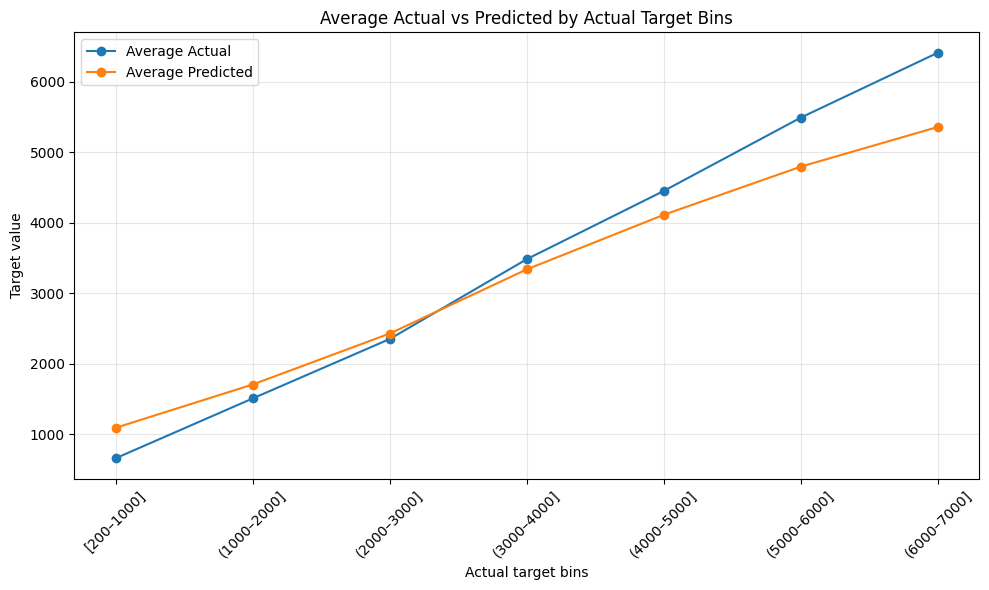

,bin,avg_actual,avg_predicted,share
0,[200-1000],657.62,1090.150024,19.13
1,(1000-2000],1506.86,1704.930054,31.57
2,(2000-3000],2350.80,2428.399902,21.88
3,(3000-4000],3484.12,3339.149902,8.28
4,(4000-5000],4453.36,4114.200195,6.61
5,(5000-6000],5494.29,4797.879883,4.90
6,(6000-7000],6415.65,5361.069824,7.64


In [48]:
plot_actual_vs_predicted_by_bins(
    y_true=y_test,
    y_pred=y_test_pred
)

The analysis shows that the model overestimates in the low amount groups and does the opposite in the high amount groups.

There are many methods for solving this problem (pre-hoc and post-hoc calibration), but in this case we use one specific approach and look at the final result. How strict our approach should be depends on the business task as well as on general regulations.

Segment-Aware Huber + Threshold Loss

In [60]:
def exceeds_segment_threshold(y_true, y_pred):
    errors = y_pred - y_true                                           
    thresholds = np.zeros_like(y_true, dtype=float)                  

    low_segment = (y_true <= 2000)                                    
    mid_segment = (y_true > 2000) & (y_true <= 4000)                   
    high_segment = (y_true > 4000)                                     

    thresholds[low_segment] = np.maximum(200, 0.2 * y_true[low_segment])  
    thresholds[mid_segment] = np.maximum(400, 0.2 * y_true[mid_segment])  

    exceeds = np.zeros_like(y_true, dtype=bool)                        
    low_mid = low_segment | mid_segment                                
    exceeds[low_mid] = errors[low_mid] > thresholds[low_mid]            

    return exceeds, thresholds, errors                                 

def segment_aware_huber(y_true, y_pred):
    errors = y_pred - y_true                                            
    abs_errors = np.abs(errors)                                         

    low_segment = (y_true <= 2000)                                     
    mid_segment = (y_true > 2000) & (y_true <= 4000)                   
    high_segment = (y_true > 4000)                                     

    delta = np.zeros_like(y_true, dtype=float)                          
    delta[low_segment] = 100                                            
    delta[mid_segment] = 200                                            
    delta[high_segment] = 400                                          

    is_small = abs_errors <= delta                                     
    grad = np.where(is_small, 2.0 * errors, 2.0 * delta * np.sign(errors)) 
    hess = np.where(is_small, 2.0, 0.1)                               

    exceeds, thresholds, _ = exceeds_segment_threshold(y_true, y_pred)   
    over_penalty_weight = np.zeros_like(y_true, dtype=float)             
    over_penalty_weight[low_segment] = 10.0                              
    over_penalty_weight[mid_segment] = 3.0                               
    over_penalty_weight[high_segment] = 0.0                              

    if np.any(exceeds):                                                 
        exceed_amount = (y_pred[exceeds] - y_true[exceeds] - thresholds[exceeds])  
        extra_grad = np.zeros_like(y_true, dtype=float)                 
        extra_hess = np.zeros_like(y_true, dtype=float)                  
        extra_grad[exceeds] = 2.0 * exceed_amount * over_penalty_weight[exceeds]  
        extra_hess[exceeds] = 2.0 * over_penalty_weight[exceeds]         
        grad += extra_grad                                             
        hess += extra_hess                                             

    under_mask = (errors < 0)                                            
    under_weight = np.zeros_like(y_true, dtype=float)                    
    under_weight[low_segment] = 0.0                                      
    under_weight[mid_segment] = 0.0                                      
    under_weight[high_segment] = 6.0 

    if np.any(under_mask):                                             
        grad[under_mask] += 2.0 * errors[under_mask] * under_weight[under_mask]  
        hess[under_mask] += 2.0 * under_weight[under_mask]              

    return grad, hess                                                   


xgb_model = XGBRegressor(
    objective=segment_aware_huber,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbosity=0
)

param_distributions = {
    "n_estimators": [100, 200, 300],              
    "max_depth": [3, 4, 5],                 
    "learning_rate": [0.01, 0.05, 0.1, 0.2],      
    "subsample": [0.5, 0.6, 0.7, 0.8, 1.0],                 
    "colsample_bytree": [0.6, 0.8, 1.0],          
    "gamma": [0, 0.1, 0.3, 0.5],                  
    "reg_lambda": [1, 5, 10],                     
    "reg_alpha": [0.1, 0.5, 1]                 
}
 
print("Starting hyperparameter tuning with 5-fold cross-validation...")
random_search = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=param_distributions,
    n_iter=50,  
    scoring='neg_mean_squared_error',
    cv=5,  
    verbose=1,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    return_train_score=True
)
 
random_search.fit(X_train, y_train)
 
best_xgb_model = random_search.best_estimator_
 
print(f"\nBest hyperparameters found:")
for param, value in random_search.best_params_.items():
    print(f"  {param}: {value}")

Starting hyperparameter tuning with 5-fold cross-validation...
Fitting 5 folds for each of 50 candidates, totalling 250 fits

Best hyperparameters found:
  subsample: 0.6
  reg_lambda: 5
  reg_alpha: 1
  n_estimators: 300
  max_depth: 3
  learning_rate: 0.01
  gamma: 0.1
  colsample_bytree: 0.8


In [58]:
feat_importances = best_xgb_model.feature_importances_
feature_importance_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': feat_importances
}).sort_values('Importance', ascending=False)
feature_importance_df

,Feature,Importance
5,Min_transfer_In,0.293154
2,Inc_in,0.242798
6,Turnover,0.064282
1,Liab_Tot,0.051904
8,Salary,0.050746
0,Inc_Past,0.045277
3,Transfers_out,0.040534
11,Transfers_in,0.037452
9,Inc_6M,0.030900
16,Inc_Past_max,0.028764


Drop the variables that the model does not use and train the model again

In [59]:
X_train.drop(columns=['Balance', 'Inc_Past_avg', 'salary_payment_ratio', 'transfers_in_out_ratio'], inplace=True)
X_test.drop(columns=['Balance', 'Inc_Past_avg', 'salary_payment_ratio', 'transfers_in_out_ratio'], inplace=True)

Look at the results of the final model

In [61]:
y_train_pred = best_xgb_model.predict(X_train)
y_test_pred  = best_xgb_model.predict(X_test)
train_metrics = regression_metrics(y_train, y_train_pred)
test_metrics  = regression_metrics(y_test, y_test_pred)
metrics_df = pd.DataFrame(
    [train_metrics, test_metrics],
    columns=["R2", "MAPE", "MAE"],
    index=["Train", "Test"]
)
print("\nXGBoost evaluation:")
print(metrics_df)


XGBoost evaluation:
             R2      MAPE         MAE
Train  0.723932  0.344856  664.774160
Test   0.711598  0.346006  671.237418


In [62]:
train_acc = within_error_accuracy(y_train, y_train_pred)
test_acc  = within_error_accuracy(y_test, y_test_pred)

accuracy_df = pd.DataFrame([train_acc, test_acc], index=["Train", "Test"])

print("\nWithin-error accuracy (%):")
print(accuracy_df)


Within-error accuracy (%):
       within_5%  within_10%  within_15%  within_20%
Train       9.78       21.14       31.16       40.26
Test        9.36       20.80       30.88       39.84


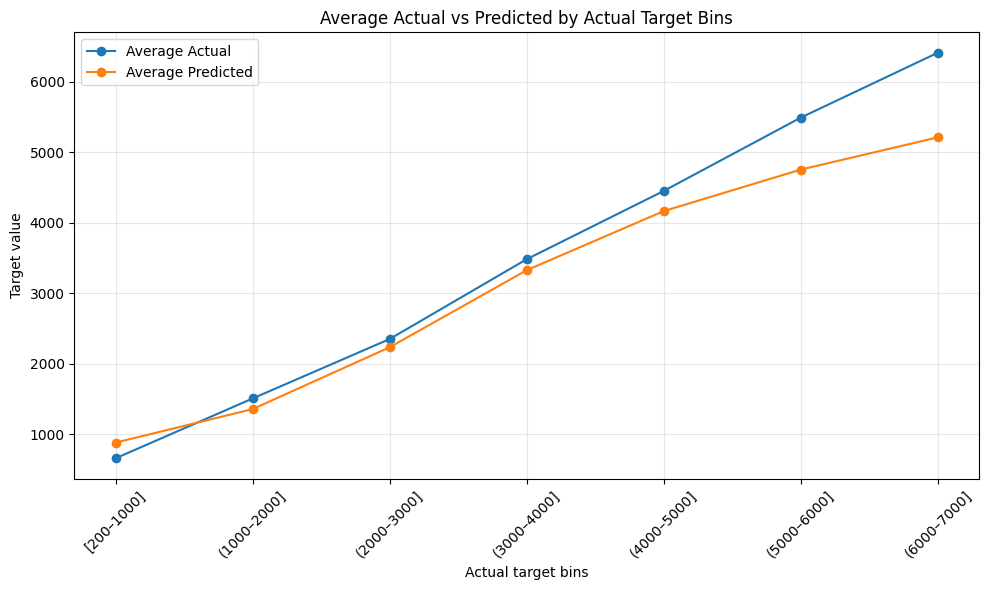

,bin,avg_actual,avg_predicted,share
0,[200-1000],657.62,880.260010,19.13
1,(1000-2000],1506.86,1356.040039,31.57
2,(2000-3000],2350.80,2233.879883,21.88
3,(3000-4000],3484.12,3327.860107,8.28
4,(4000-5000],4453.36,4167.049805,6.61
5,(5000-6000],5494.29,4756.220215,4.90
6,(6000-7000],6415.65,5213.620117,7.64


In [63]:
plot_actual_vs_predicted_by_bins(
    y_true=y_test,
    y_pred=y_test_pred
)

This is our final model. We still have a slight underestimation in the high amounts, which could be fixed by making the parameters in the calibration part even stricter. Naturally, in practice the model should be evaluated in much more depth. For example, the segment on which the model was trained and has to work matters; a more detailed analysis by variable is also needed to avoid discriminating against clients on any ground, and so on. At this stage we can add the interpretation part of the final model.

Look at the top 15 variables (Split-Based)

Feature Importances:
            Feature  Importance
5   Min_transfer_In    0.309105
2            Inc_in    0.242181
6          Turnover    0.071044
8            Salary    0.057806
1          Liab_Tot    0.048367
0          Inc_Past    0.039634
3     Transfers_out    0.035700
14     Inc_Past_max    0.034241
11     Transfers_in    0.031898
13         Payments    0.029714
4         Payment_L    0.027850
9            Inc_6M    0.027585
12             Loan    0.014171
16          Bal_Cur    0.013535
7      Transactions    0.010082


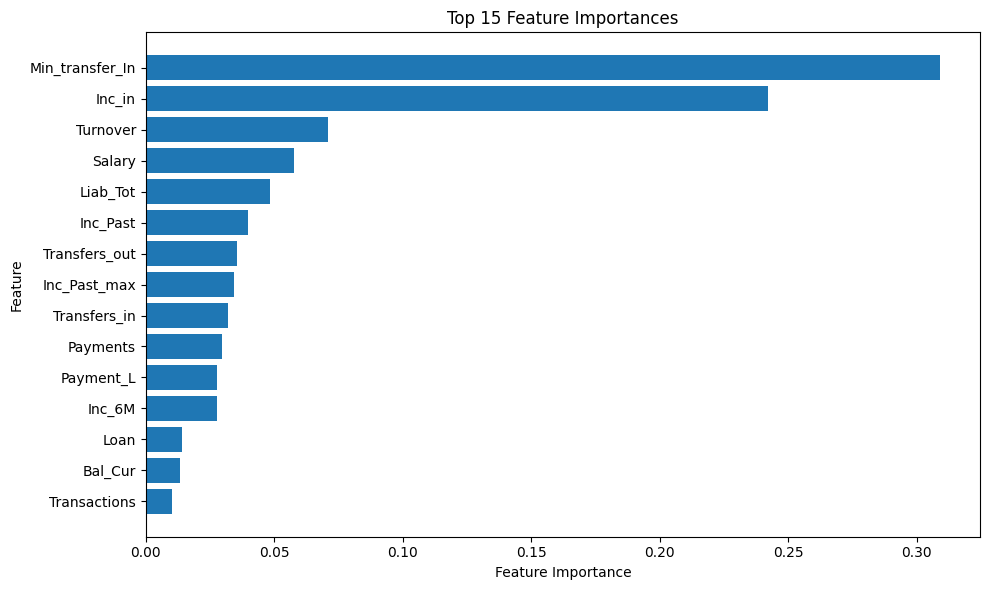

In [65]:
feat_importances = best_xgb_model.feature_importances_
feature_importance_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': feat_importances
}).sort_values('Importance', ascending=False)
print("Feature Importances:")
print(feature_importance_df.head(15))

top_features = feature_importance_df.head(15)
plt.figure(figsize=(10, 6))
plt.barh(top_features['Feature'][::-1],top_features['Importance'][::-1])
plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.title(f'Top {len(top_features)} Feature Importances')
plt.tight_layout()
plt.show()

'Client's minimum incoming payment' and 'Client's incoming payments' are the most frequently used variables in the model.

Dependence plots of the target and the top 6 variables

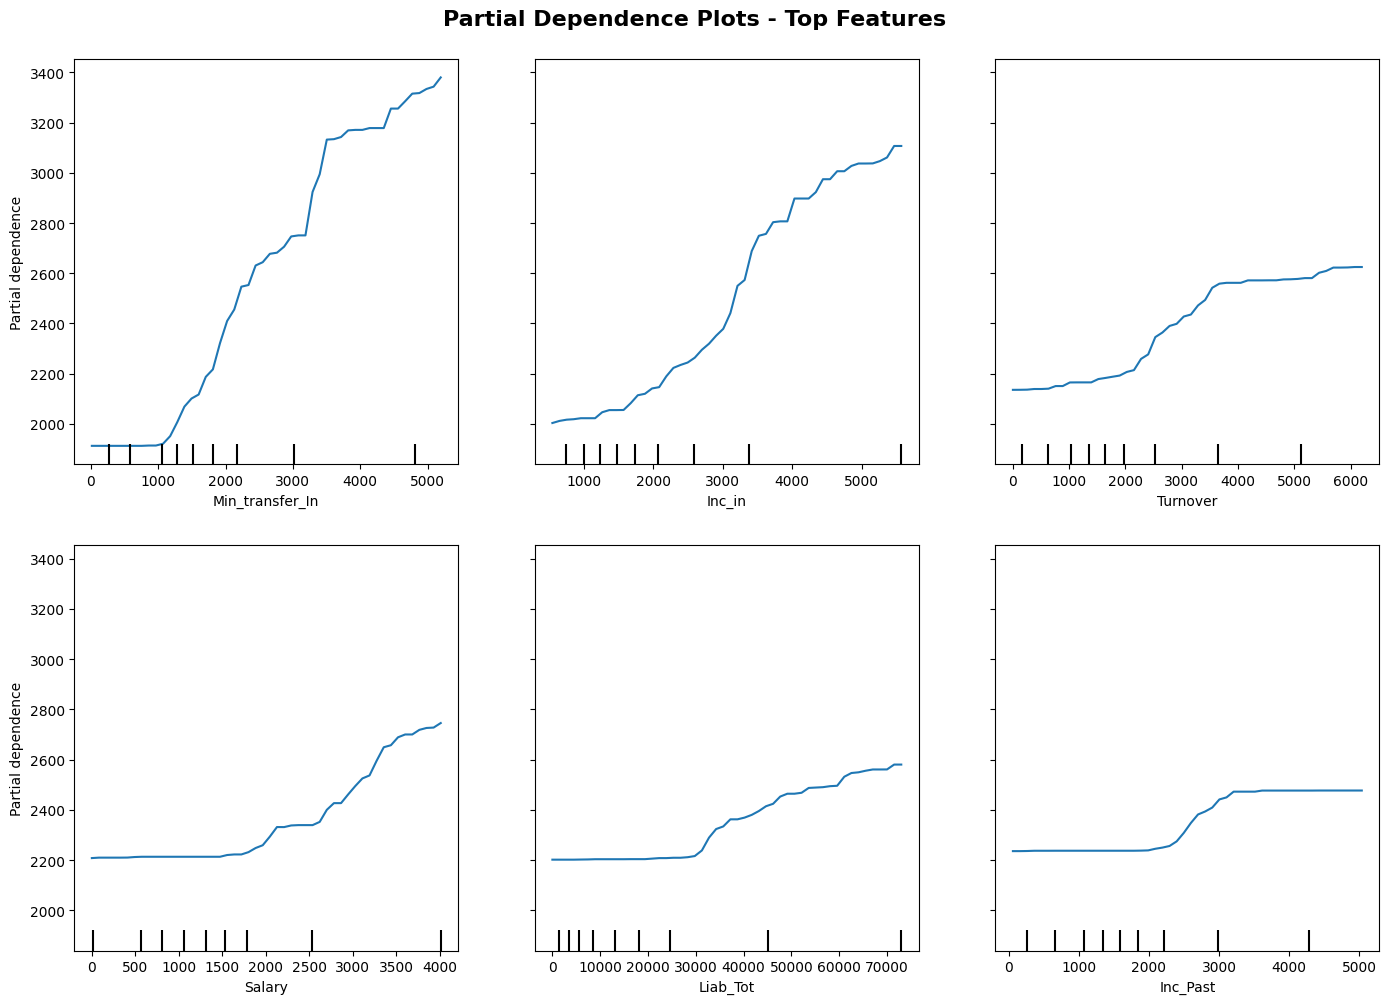

In [66]:
top_n_features = 6
top_feature_names = feature_importance_df.head(top_n_features)['Feature'].tolist()

fig, ax = plt.subplots(figsize=(14, 10))
PartialDependenceDisplay.from_estimator(
    best_xgb_model,
    X_train,
    features=top_feature_names,
    ax=ax,
    n_jobs=-1,
    grid_resolution=50
)
plt.suptitle('Partial Dependence Plots - Top Features', fontsize=16, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()

Analysis of the variables with the biggest effect on the dependent variable (Top 15)

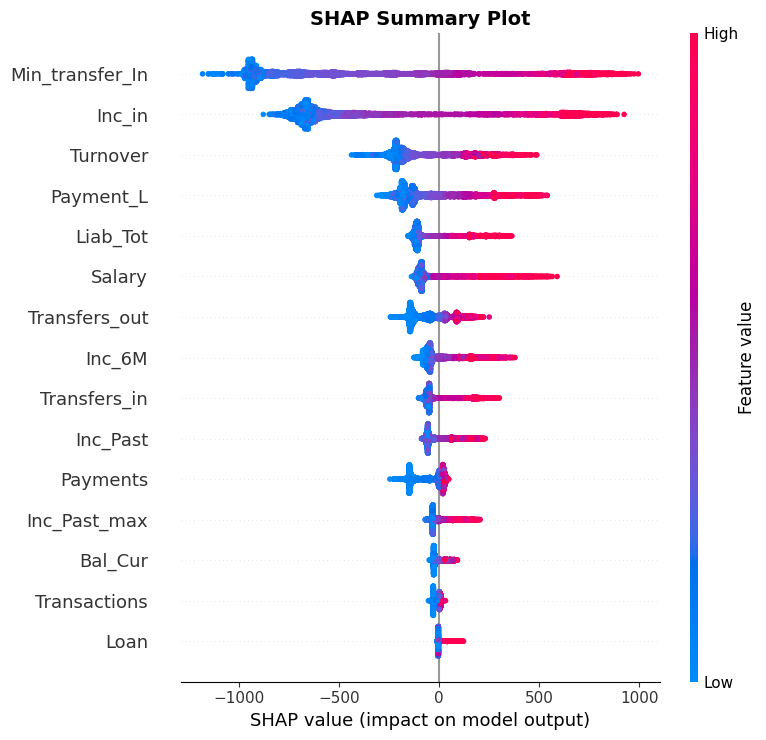

In [68]:
sample_size = 5000 
X_sample = X_train.sample(n=sample_size, random_state=RANDOM_STATE)
explainer = shap.TreeExplainer(best_xgb_model)
shap_values = explainer.shap_values(X_sample)

plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, X_sample, show=False, max_display=15)
plt.title('SHAP Summary Plot', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

Here too we can see that 'Client's minimum incoming payment' and 'Client's incoming payments' have the biggest effect on the change in the target value

Done